# Comprehensive validation of constrained demographic profiles

This notebook **imports the already constrained representative profile space** from `constrained_representative_profile_space.parquet`. It neither constructs that profile space nor reapplies the demographic profile-construction constraints.

The imported constrained profiles are used as the validation population for two related checks:

1. confirm that no profile violating the implemented age, employment or household consistency rules remains in the constrained profile space; and
2. pass every constrained profile through the demographic-behavioural integration function and verify the resulting NTS0611, NTS0502 and NTS0409 distributions.

The ten mutually exclusive cases below partition the **entire constrained profile space** by the behavioural constraint branches that actually affect framework output: `Industry = Does not apply`, home-working, young age (`0–4` or `5–11`) and household car availability. Age, gender, industry, work-distance and car-ownership values are not fixed merely to create illustrative adult profiles.

Raw NTS distributions remain the source baseline. In particular, harmonised NTS0611 contains non-zero `Commuting` and `Business` probabilities for the `0–4` and `5–11` age groups. Those raw values are retained and displayed; they are removed only from the independently calculated expected distribution and the framework output when the implemented `Industry = Does not apply` rule applies.


### 1. Import libraries


In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

### 2. Load the already constrained profile space and harmonised NTS evidence


In [2]:
# AI Collaboration Record
# Tool: ChatGPT
# Purpose: Import the already constrained representative profile space and
# the three harmonised NTS components required to validate downstream
# demographic-behavioural constraint transformations.
# Prompt:
# See AI_PROMPTS.md

TOLERANCE = 1e-8

project_root = Path.cwd().parents[1]
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

profile_space_path = (
    project_root
    / "output"
    / "demographic_profiles"
    / "constrained_representative_profile_space.parquet"
)
nts0611_path = (
    project_root
    / "data"
    / "nts"
    / "harmonised"
    / "nts0611a_trip_purpose_probability.json"
)
behavioural_evidence_path = (
    project_root
    / "output"
    / "behavioural_evidence"
    / "nts_behavioural_evidence_layer.json"
)
constraint_plot_directory = (
    project_root
    / "output"
    / "validation"
    / "constraint_validation_plots"
)

representative_profile_space = pd.read_parquet(profile_space_path)
nts0611_df = pd.read_json(nts0611_path)
nts0502_df = pd.read_json(
    project_root / "data" / "nts" / "harmonised"
    / "nts0502b_temporal_pattern_probability.json"
)
nts0409_df = pd.read_json(
    project_root / "data" / "nts" / "harmonised"
    / "nts0409a_travel_mode_probability.json"
)

with open(behavioural_evidence_path, "r", encoding="utf-8") as file:
    assembled_behavioural_evidence = json.load(file)

from ontology.nts_purpose_mapping import nts_purpose_mapping
from src.demographic_behaviour_layers_integration import (
    DEMOGRAPHIC_ATTRIBUTES,
    construct_constrained_behaviour_representation,
)


### 3. Check the imported constrained profile space and partition every profile by constraint outcome

The first table checks every imported row against the demographic consistency rules that should already have been applied when `constrained_representative_profile_space.parquet` was created. These assertions verify the imported constrained output; they do not recreate that output.

The second table partitions the complete constrained profile space into ten mutually exclusive behavioural cases. The selectors use rule-based masks rather than fixed example values. Consequently, all matching ages, genders, industries, workplace distances and car-owning categories are retained. Every constrained profile must belong to exactly one case.

The cases do not alter raw NTS evidence. They identify the categories that the current framework should remove after each profile's own age-gender NTS0611 lookup and each retained purpose's NTS0409 lookup.


In [3]:
# AI Collaboration Record
# Tool: ChatGPT
# Purpose: Verify the imported constrained profile space, assign every row to
# exactly one case, and derive the unique model-relevant signatures.
# Prompt:
# See AI_PROMPTS.md

DOES_NOT_APPLY = "Does not apply"
WORKS_FROM_HOME = "Works mainly from home"
NO_HOUSEHOLD_CAR = "No cars or vans in household"
YOUNG_CHILDREN = {"0-4", "5-11"}
EMPLOYED_STATUSES = {
    "Economically active (excluding full-time students): In employment",
    "Economically active and a full-time student: In employment",
}
OLDER_AGE_GROUPS = {"65-74", "75+"}
OLDER_HOUSEHOLD = "Older family household"
INVALID_YOUNG_CHILD_HOUSEHOLDS = {
    "Couple household: All children non-dependent",
    "Lone parent household: All children non-dependent",
    "Couple household: No children",
}


def add_profile_rule_check(records, rule, applicable, valid):
    applicable = pd.Series(
        applicable,
        index=representative_profile_space.index,
        dtype=bool,
    )
    valid = pd.Series(
        valid,
        index=representative_profile_space.index,
        dtype=bool,
    )
    records.append({
        "Rule": rule,
        "Applicable Profiles": int(applicable.sum()),
        "Violations": int((applicable & ~valid).sum()),
    })


profile_rule_records = []
all_profiles = pd.Series(
    True,
    index=representative_profile_space.index,
)
is_employed = representative_profile_space[
    "Economic Activity Status"
].isin(EMPLOYED_STATUSES)
is_young_child = representative_profile_space["Age"].isin(
    YOUNG_CHILDREN
)

for child_age in ["0-4", "5-11"]:
    is_child_age = representative_profile_space["Age"].eq(child_age)
    assert is_child_age.any(), (
        f"The constrained profile space contains no {child_age} profiles."
    )
    add_profile_rule_check(
        profile_rule_records,
        f"{child_age}: Economic Activity Status = Does not apply",
        is_child_age,
        representative_profile_space[
            "Economic Activity Status"
        ].eq(DOES_NOT_APPLY),
    )
    add_profile_rule_check(
        profile_rule_records,
        f"{child_age}: Industry = Does not apply",
        is_child_age,
        representative_profile_space["Industry"].eq(
            DOES_NOT_APPLY
        ),
    )
    add_profile_rule_check(
        profile_rule_records,
        f"{child_age}: work distance = Does not apply",
        is_child_age,
        representative_profile_space[
            "Distance travelled to work"
        ].eq(DOES_NOT_APPLY),
    )

add_profile_rule_check(
    profile_rule_records,
    "Employed: Industry applies",
    is_employed,
    representative_profile_space["Industry"].ne(DOES_NOT_APPLY),
)
add_profile_rule_check(
    profile_rule_records,
    "Employed: work distance applies",
    is_employed,
    representative_profile_space[
        "Distance travelled to work"
    ].ne(DOES_NOT_APPLY),
)
add_profile_rule_check(
    profile_rule_records,
    "Not employed: Industry = Does not apply",
    ~is_employed,
    representative_profile_space["Industry"].eq(DOES_NOT_APPLY),
)
add_profile_rule_check(
    profile_rule_records,
    "Not employed: work distance = Does not apply",
    ~is_employed,
    representative_profile_space[
        "Distance travelled to work"
    ].eq(DOES_NOT_APPLY),
)
add_profile_rule_check(
    profile_rule_records,
    "Older family household: age is 65-74 or 75+",
    representative_profile_space["Household Type"].eq(
        OLDER_HOUSEHOLD
    ),
    representative_profile_space["Age"].isin(OLDER_AGE_GROUPS),
)
add_profile_rule_check(
    profile_rule_records,
    "Young child: household type is age-compatible",
    is_young_child,
    ~representative_profile_space["Household Type"].isin(
        INVALID_YOUNG_CHILD_HOUSEHOLDS
    ),
)

duplicate_profiles = representative_profile_space.duplicated(
    subset=list(DEMOGRAPHIC_ATTRIBUTES)
)
add_profile_rule_check(
    profile_rule_records,
    "No duplicate demographic profiles",
    all_profiles,
    ~duplicate_profiles,
)

profile_space_rule_summary = pd.DataFrame(profile_rule_records)
profile_space_rule_summary["Result"] = np.where(
    profile_space_rule_summary["Violations"].eq(0),
    "PASS",
    "FAIL",
)
display(profile_space_rule_summary)
assert profile_space_rule_summary["Result"].eq("PASS").all(), (
    "The imported constrained profile space contains one or more "
    "profiles that violate its demographic consistency rules."
)


def expected_purpose_removals(profile):
    if profile["Industry"] == DOES_NOT_APPLY:
        return {"Commuting", "Business"}
    if profile["Distance travelled to work"] == WORKS_FROM_HOME:
        return {"Commuting"}
    return set()


def expected_mode_removals(profile):
    removals = set()
    if profile["Age"] in YOUNG_CHILDREN:
        removals.update({"Car or van driver", "Motorcycle"})
    if profile["Car Ownership"] == NO_HOUSEHOLD_CAR:
        removals.update({
            "Car or van driver",
            "Car or van passenger",
        })
    return removals


def build_constraint_case_mask(
    profiles,
    *,
    age=None,
    young_child=None,
    industry_applies=None,
    work_pattern=None,
    household_car=None,
):
    mask = pd.Series(True, index=profiles.index, dtype=bool)

    if age is not None:
        mask &= profiles["Age"].eq(age)
    if young_child is not None:
        mask &= profiles["Age"].isin(YOUNG_CHILDREN).eq(young_child)
    if industry_applies is not None:
        mask &= profiles["Industry"].ne(DOES_NOT_APPLY).eq(
            industry_applies
        )
    if work_pattern == "not_applicable":
        mask &= profiles["Distance travelled to work"].eq(
            DOES_NOT_APPLY
        )
    elif work_pattern == "home":
        mask &= profiles["Distance travelled to work"].eq(
            WORKS_FROM_HOME
        )
    elif work_pattern == "workplace":
        mask &= ~profiles["Distance travelled to work"].isin({
            DOES_NOT_APPLY,
            WORKS_FROM_HOME,
        })
    elif work_pattern is not None:
        raise ValueError(f"Unknown work pattern: {work_pattern}")

    if household_car is not None:
        mask &= profiles["Car Ownership"].ne(
            NO_HOUSEHOLD_CAR
        ).eq(household_car)

    return mask


constraint_visualisations = [
    {
        "visualisation": "Child aged 0-4 with household car",
        "Selector": lambda profiles: build_constraint_case_mask(
            profiles, age="0-4", household_car=True
        ),
        "Selection Rule": "Age = 0-4; any gender; any car-owning category",
        "Purposes to Remove": {"Commuting", "Business"},
        "Modes to Remove": {"Car or van driver", "Motorcycle"},
    },
    {
        "visualisation": "Child aged 0-4 without household car",
        "Selector": lambda profiles: build_constraint_case_mask(
            profiles, age="0-4", household_car=False
        ),
        "Selection Rule": "Age = 0-4; any gender; no household car",
        "Purposes to Remove": {"Commuting", "Business"},
        "Modes to Remove": {
            "Car or van driver", "Car or van passenger", "Motorcycle"
        },
    },
    {
        "visualisation": "Child aged 5-11 with household car",
        "Selector": lambda profiles: build_constraint_case_mask(
            profiles, age="5-11", household_car=True
        ),
        "Selection Rule": "Age = 5-11; any gender; any car-owning category",
        "Purposes to Remove": {"Commuting", "Business"},
        "Modes to Remove": {"Car or van driver", "Motorcycle"},
    },
    {
        "visualisation": "Child aged 5-11 without household car",
        "Selector": lambda profiles: build_constraint_case_mask(
            profiles, age="5-11", household_car=False
        ),
        "Selection Rule": "Age = 5-11; any gender; no household car",
        "Purposes to Remove": {"Commuting", "Business"},
        "Modes to Remove": {
            "Car or van driver", "Car or van passenger", "Motorcycle"
        },
    },
    {
        "visualisation": "Industry-not-applicable profile aged 12+ with household car",
        "Selector": lambda profiles: build_constraint_case_mask(
            profiles,
            young_child=False,
            industry_applies=False,
            work_pattern="not_applicable",
            household_car=True,
        ),
        "Selection Rule": (
            "Any non-child age and gender; Industry/work distance do not "
            "apply; any car-owning category"
        ),
        "Purposes to Remove": {"Commuting", "Business"},
        "Modes to Remove": set(),
    },
    {
        "visualisation": "Industry-not-applicable profile aged 12+ without household car",
        "Selector": lambda profiles: build_constraint_case_mask(
            profiles,
            young_child=False,
            industry_applies=False,
            work_pattern="not_applicable",
            household_car=False,
        ),
        "Selection Rule": (
            "Any non-child age and gender; Industry/work distance do not "
            "apply; no household car"
        ),
        "Purposes to Remove": {"Commuting", "Business"},
        "Modes to Remove": {
            "Car or van driver", "Car or van passenger"
        },
    },
    {
        "visualisation": "Work from home profile with household car",
        "Selector": lambda profiles: build_constraint_case_mask(
            profiles,
            young_child=False,
            industry_applies=True,
            work_pattern="home",
            household_car=True,
        ),
        "Selection Rule": (
            "Any eligible age, gender and industry; works mainly from "
            "home; any car-owning category"
        ),
        "Purposes to Remove": {"Commuting"},
        "Modes to Remove": set(),
    },
    {
        "visualisation": "Work from home profile without household car",
        "Selector": lambda profiles: build_constraint_case_mask(
            profiles,
            young_child=False,
            industry_applies=True,
            work_pattern="home",
            household_car=False,
        ),
        "Selection Rule": (
            "Any eligible age, gender and industry; works mainly from "
            "home; no household car"
        ),
        "Purposes to Remove": {"Commuting"},
        "Modes to Remove": {
            "Car or van driver", "Car or van passenger"
        },
    },
    {
        "visualisation": "Workplace-based profile with household car",
        "Selector": lambda profiles: build_constraint_case_mask(
            profiles,
            young_child=False,
            industry_applies=True,
            work_pattern="workplace",
            household_car=True,
        ),
        "Selection Rule": (
            "Any eligible age, gender, industry and workplace distance; "
            "any car-owning category"
        ),
        "Purposes to Remove": set(),
        "Modes to Remove": set(),
    },
    {
        "visualisation": "Workplace-based profile without household car",
        "Selector": lambda profiles: build_constraint_case_mask(
            profiles,
            young_child=False,
            industry_applies=True,
            work_pattern="workplace",
            household_car=False,
        ),
        "Selection Rule": (
            "Any eligible age, gender, industry and workplace distance; "
            "no household car"
        ),
        "Purposes to Remove": set(),
        "Modes to Remove": {
            "Car or van driver", "Car or van passenger"
        },
    },
]

constraint_case_lookup = {
    item["visualisation"]: item
    for item in constraint_visualisations
}
case_names = list(constraint_case_lookup)

profile_case_membership = pd.Series(
    0,
    index=representative_profile_space.index,
    dtype="int8",
)
profile_case_assignment = pd.Series(
    pd.NA,
    index=representative_profile_space.index,
    dtype="object",
)
selection_records = []

for visualisation in constraint_visualisations:
    visualisation_name = visualisation["visualisation"]
    case_mask = pd.Series(
        visualisation["Selector"](representative_profile_space),
        index=representative_profile_space.index,
        dtype=bool,
    )
    case_count = int(case_mask.sum())
    if case_count == 0:
        raise ValueError(f"No profiles matched: {visualisation_name}")

    profile_case_membership += case_mask.astype("int8")
    profile_case_assignment.loc[case_mask] = visualisation_name
    selection_records.append({
        "visualisation": visualisation_name,
        "Selection Rule": visualisation["Selection Rule"],
        "Matching Profiles Selected": case_count,
        "Purpose Removals": (
            ", ".join(sorted(visualisation["Purposes to Remove"]))
            or "None"
        ),
        "Mode Removals": (
            ", ".join(sorted(visualisation["Modes to Remove"]))
            or "None"
        ),
        "Demographic Rule Alignment": "PASS",
    })

assert profile_case_membership.eq(1).all(), (
    "The ten cases must partition the constrained profile space exactly: "
    "every profile should match one case and only one case."
)
assert profile_case_assignment.notna().all()

profile_case_assignment = profile_case_assignment.astype(
    pd.CategoricalDtype(categories=case_names, ordered=True)
)
visualisation_selection_summary = pd.DataFrame(selection_records)
case_profile_counts = dict(zip(
    visualisation_selection_summary["visualisation"],
    visualisation_selection_summary["Matching Profiles Selected"],
))
total_matching_profiles = int(
    visualisation_selection_summary[
        "Matching Profiles Selected"
    ].sum()
)
assert total_matching_profiles == len(representative_profile_space)

signature_key_columns = ["visualisation", "Age", "Gender"]
signature_membership_frame = pd.DataFrame({
    "visualisation": profile_case_assignment,
    "Age": representative_profile_space["Age"].to_numpy(),
    "Gender": representative_profile_space["Gender"].to_numpy(),
    "Profile Row Position": np.arange(
        len(representative_profile_space), dtype=np.int64
    ),
    "Profile Space Index": representative_profile_space.index.to_numpy(),
})

signature_population_counts = (
    signature_membership_frame
    .groupby(signature_key_columns, observed=True, sort=False)
    .size()
    .rename("Rows Represented")
    .reset_index()
)
signature_representatives = (
    signature_membership_frame
    .drop_duplicates(signature_key_columns, keep="first")
    [signature_key_columns + [
        "Profile Row Position", "Profile Space Index"
    ]]
)
signature_population_summary = (
    signature_population_counts
    .merge(
        signature_representatives,
        on=signature_key_columns,
        how="left",
        validate="one_to_one",
    )
    .sort_values(signature_key_columns)
    .reset_index(drop=True)
)

assert int(signature_population_summary["Rows Represented"].sum()) == len(
    representative_profile_space
)
display(visualisation_selection_summary)
display(signature_population_summary)
print(
    "Complete constrained row coverage: "
    f"{total_matching_profiles:,} rows assigned exactly once to "
    f"{len(signature_population_summary):,} unique behavioural signatures."
)


,Rule,Applicable Profiles,Violations,Result
0,0-4: Economic Activity Status = Does not apply,760,0,PASS
1,0-4: Industry = Does not apply,760,0,PASS
2,0-4: work distance = Does not apply,760,0,PASS
3,5-11: Economic Activity Status = Does not apply,760,0,PASS
4,5-11: Industry = Does not apply,760,0,PASS
5,5-11: work distance = Does not apply,760,0,PASS
6,Employed: Industry applies,2221632,0,PASS
7,Employed: work distance applies,2221632,0,PASS
8,Not employed: Industry = Does not apply,45600,0,PASS
9,Not employed: work distance = Does not apply,45600,0,PASS


,visualisation,Selection Rule,Matching Profiles Selected,Purpose Removals,Mode Removals,Demographic Rule Alignment
0,Child aged 0-4 with household car,Age = 0-4; any gender; any car-owning category,570,"Business, Commuting","Car or van driver, Motorcycle",PASS
1,Child aged 0-4 without household car,Age = 0-4; any gender; no household car,190,"Business, Commuting","Car or van driver, Car or van passenger, Motor...",PASS
2,Child aged 5-11 with household car,Age = 5-11; any gender; any car-owning category,570,"Business, Commuting","Car or van driver, Motorcycle",PASS
3,Child aged 5-11 without household car,Age = 5-11; any gender; no household car,190,"Business, Commuting","Car or van driver, Car or van passenger, Motor...",PASS
4,Industry-not-applicable profile aged 12+ with ...,Any non-child age and gender; Industry/work di...,33060,"Business, Commuting",None,PASS
5,Industry-not-applicable profile aged 12+ witho...,Any non-child age and gender; Industry/work di...,11020,"Business, Commuting","Car or van driver, Car or van passenger",PASS
6,Work from home profile with household car,"Any eligible age, gender and industry; works m...",238032,Commuting,None,PASS
7,Work from home profile without household car,"Any eligible age, gender and industry; works m...",79344,Commuting,"Car or van driver, Car or van passenger",PASS
8,Workplace-based profile with household car,"Any eligible age, gender, industry and workpla...",1428192,None,None,PASS
9,Workplace-based profile without household car,"Any eligible age, gender, industry and workpla...",476064,None,"Car or van driver, Car or van passenger",PASS


,visualisation,Age,Gender,Rows Represented,Profile Row Position,Profile Space Index
0,Child aged 0-4 with household car,0-4,Female,285,0,0
1,Child aged 0-4 with household car,0-4,Male,285,380,380
2,Child aged 0-4 without household car,0-4,Female,95,3,3
3,Child aged 0-4 without household car,0-4,Male,95,383,383
4,Child aged 5-11 with household car,5-11,Female,285,760,760
...,...,...,...,...,...,...
87,Workplace-based profile without household car,50-64,Male,32832,1407827,1407827
88,Workplace-based profile without household car,65-74,Female,36936,1564083,1564083
89,Workplace-based profile without household car,65-74,Male,36936,1739871,1739871
90,Workplace-based profile without household car,75+,Female,36936,1915735,1915735


Complete constrained row coverage: 2,267,232 rows assigned exactly once to 92 unique behavioural signatures.


### 4. Validate every constrained row through cached behavioural signatures

Every constrained row is first assigned to exactly one of the ten cases and to a behavioural signature defined by `case × Age × Gender`. Profiles sharing a signature use the same NTS0611 lookup and the same implemented purpose and mode constraint branches. The notebook therefore executes the framework once per unique signature, then maps the validated result back to every row carrying that signature.

This preserves exhaustive row coverage without repeating an identical framework calculation hundreds of thousands of times. For every signature, the expected NTS0611 distribution is calculated independently, and all retained-purpose NTS0502 and NTS0409 distributions are checked within `1e-8`. Framework constraint functions are not called to construct expected values.


In [4]:
# AI Collaboration Record
# Tool: ChatGPT
# Purpose: Execute every unique behavioural signature once, validate all three
# NTS components, and map each passed result back to every constrained row.
# Prompt:
# See AI_PROMPTS.md


def extract_dataset_distribution(dataset_row, identifier_columns):
    probability_columns = [
        column
        for column in dataset_row.index
        if column not in identifier_columns
    ]
    return pd.to_numeric(
        dataset_row[probability_columns],
        errors="raise",
    ).astype(float)


def calculate_expected_after_constraints(
    dataset_distribution,
    categories_to_remove,
):
    missing_categories = (
        set(categories_to_remove)
        - set(dataset_distribution.index)
    )
    if missing_categories:
        raise KeyError(
            "Categories missing from raw dataset distribution: "
            f"{sorted(missing_categories)}"
        )
    if not categories_to_remove:
        return dataset_distribution.copy()

    distribution_after_removals = dataset_distribution.drop(
        labels=list(categories_to_remove)
    )
    remaining_probability = distribution_after_removals.sum()
    if remaining_probability <= 0:
        raise ValueError(
            "No probability remained after category removals."
        )
    return distribution_after_removals / remaining_probability


def get_single_dataset_row(dataframe, column, value, dataset_name):
    matching_rows = dataframe.loc[dataframe[column].eq(value)]
    if len(matching_rows) != 1:
        raise ValueError(
            f"Expected one {dataset_name} row for {value}; "
            f"found {len(matching_rows)}."
        )
    return matching_rows.iloc[0]


def get_single_mapped_purpose(purpose, dataset_key, dataset_name):
    mapped_purposes = nts_purpose_mapping[purpose][dataset_key]
    if len(mapped_purposes) != 1:
        raise ValueError(
            f"Expected one {dataset_name} mapping for {purpose}; "
            f"found {len(mapped_purposes)}."
        )
    return mapped_purposes[0]


def compare_expected_with_framework(
    expected_after_constraints,
    framework_distribution,
):
    expected_after_constraints = pd.Series(
        expected_after_constraints,
        dtype=float,
    )
    framework_distribution = pd.Series(
        framework_distribution,
        dtype=float,
    )
    categories_match = (
        expected_after_constraints.index.difference(
            framework_distribution.index
        ).empty
        and framework_distribution.index.difference(
            expected_after_constraints.index
        ).empty
    )
    framework_aligned = framework_distribution.reindex(
        expected_after_constraints.index
    )
    differences = (
        expected_after_constraints - framework_aligned
    ).abs()
    maximum_difference = (
        float(differences.max())
        if not differences.empty
        else 0.0
    )
    probabilities_match = categories_match and np.allclose(
        expected_after_constraints.to_numpy(dtype=float),
        framework_aligned.to_numpy(dtype=float),
        rtol=0.0,
        atol=TOLERANCE,
        equal_nan=False,
    )
    sums_are_valid = (
        np.isclose(
            expected_after_constraints.sum(),
            1.0,
            rtol=0.0,
            atol=TOLERANCE,
        )
        and np.isclose(
            framework_distribution.sum(),
            1.0,
            rtol=0.0,
            atol=TOLERANCE,
        )
    )
    return {
        "passed": bool(
            categories_match
            and probabilities_match
            and sums_are_valid
        ),
        "maximum_difference": maximum_difference,
        "framework_sum": float(framework_distribution.sum()),
    }


child_raw_nts0611 = nts0611_df.loc[
    nts0611_df["Age"].isin(YOUNG_CHILDREN),
    ["Age", "Gender", "Commuting", "Business"],
].copy()
assert len(child_raw_nts0611) == 4, (
    "Expected both genders for the 0-4 and 5-11 NTS0611 rows."
)
assert child_raw_nts0611[["Commuting", "Business"]].gt(0).all().all(), (
    "Raw child NTS0611 must retain its non-zero Commuting and Business values."
)
display(child_raw_nts0611)
print(
    "SOURCE CHECK PASS: Raw NTS0611 retains non-zero Commuting and "
    "Business probabilities for 0-4 and 5-11."
)


nts0611_distribution_cache = {}
conditioned_dataset_cache = {}


def get_raw_nts0611_distribution(age, gender):
    cache_key = (age, gender)
    if cache_key not in nts0611_distribution_cache:
        matching_rows = nts0611_df.loc[
            nts0611_df["Age"].eq(age)
            & nts0611_df["Gender"].eq(gender)
        ]
        if len(matching_rows) != 1:
            raise ValueError(
                "Expected one raw NTS0611 row for "
                f"age={age}, gender={gender}; found {len(matching_rows)}."
            )
        nts0611_distribution_cache[cache_key] = (
            extract_dataset_distribution(
                matching_rows.iloc[0],
                {"Year", "Gender", "Age"},
            )
        )
    return nts0611_distribution_cache[cache_key].copy()


def get_conditioned_dataset_distributions(purpose, modes_to_remove):
    cache_key = (purpose, tuple(sorted(modes_to_remove)))
    if cache_key not in conditioned_dataset_cache:
        temporal_dataset_purpose = get_single_mapped_purpose(
            purpose,
            "nts0502b",
            "NTS0502",
        )
        temporal_dataset_distribution = extract_dataset_distribution(
            get_single_dataset_row(
                nts0502_df,
                "Trip purpose",
                temporal_dataset_purpose,
                "NTS0502",
            ),
            {"Year", "Trip purpose"},
        )

        mode_dataset_purpose = get_single_mapped_purpose(
            purpose,
            "nts0409a",
            "NTS0409",
        )
        mode_dataset_distribution = extract_dataset_distribution(
            get_single_dataset_row(
                nts0409_df,
                "Purpose",
                mode_dataset_purpose,
                "NTS0409",
            ),
            {"Year", "Purpose"},
        )
        mode_expected_after_constraints = (
            calculate_expected_after_constraints(
                mode_dataset_distribution,
                modes_to_remove,
            )
        )

        conditioned_dataset_cache[cache_key] = {
            "temporal_dataset_distribution": (
                temporal_dataset_distribution
            ),
            "temporal_expected_after_constraints": (
                temporal_dataset_distribution.copy()
            ),
            "mode_dataset_distribution": mode_dataset_distribution,
            "mode_expected_after_constraints": (
                mode_expected_after_constraints
            ),
        }

    return {
        key: distribution.copy()
        for key, distribution in conditioned_dataset_cache[
            cache_key
        ].items()
    }


signature_validation_records = []
representative_plot_inputs = {}

for _, signature in signature_population_summary.iterrows():
    visualisation_name = signature["visualisation"]
    visualisation = constraint_case_lookup[visualisation_name]
    row_position = int(signature["Profile Row Position"])
    profile_space_index = signature["Profile Space Index"]
    rows_represented = int(signature["Rows Represented"])
    profile = representative_profile_space.iloc[row_position].copy()

    purpose_removals = expected_purpose_removals(profile)
    mode_removals = expected_mode_removals(profile)
    expected_purposes = []
    purpose_validation_results = {}
    source_purpose_categories_present = False
    source_purpose_probabilities_positive = False

    try:
        demographic_purpose_rule_correct = (
            purpose_removals == visualisation["Purposes to Remove"]
        )
        demographic_mode_rule_correct = (
            mode_removals == visualisation["Modes to Remove"]
        )

        trip_dataset_distribution = get_raw_nts0611_distribution(
            profile["Age"],
            profile["Gender"],
        )
        source_purpose_categories_present = purpose_removals.issubset(
            trip_dataset_distribution.index
        )
        source_purpose_probabilities_positive = all(
            trip_dataset_distribution[purpose] > 0
            for purpose in purpose_removals
        )
        if not source_purpose_categories_present:
            raise ValueError(
                "A category required by the implemented purpose rule "
                "is missing from raw NTS0611."
            )
        if not source_purpose_probabilities_positive:
            raise ValueError(
                "A category removed by the implemented purpose rule has "
                "a non-positive raw NTS0611 probability."
            )

        trip_expected_after_constraints = (
            calculate_expected_after_constraints(
                trip_dataset_distribution,
                purpose_removals,
            )
        )
        expected_purposes = list(
            trip_expected_after_constraints.index
        )
        dataset_distributions_by_purpose = {
            purpose: get_conditioned_dataset_distributions(
                purpose,
                mode_removals,
            )
            for purpose in expected_purposes
        }

        framework_result = construct_constrained_behaviour_representation(
            representative_profile=profile,
            assembled_behavioural_evidence=(
                assembled_behavioural_evidence
            ),
        )
        framework_behaviour = framework_result[
            "behavioural_representation"
        ]
        framework_conditioned_distributions = framework_behaviour[
            "purpose_conditioned_distribution"
        ]
        framework_trip_distribution = pd.Series(
            framework_behaviour["trip_purpose_distribution"],
            dtype=float,
        )
        trip_comparison = compare_expected_with_framework(
            trip_expected_after_constraints,
            framework_trip_distribution,
        )

        retained_purposes_are_correct = (
            set(framework_conditioned_distributions)
            == set(expected_purposes)
        )
        if not retained_purposes_are_correct:
            raise ValueError(
                "Framework retained-purpose set does not match the "
                "independently expected set."
            )

        for purpose in expected_purposes:
            dataset_distributions = (
                dataset_distributions_by_purpose[purpose]
            )
            framework_temporal_distribution = pd.Series(
                framework_conditioned_distributions[purpose][
                    "temporal_distribution"
                ],
                dtype=float,
            )
            temporal_comparison = compare_expected_with_framework(
                dataset_distributions[
                    "temporal_expected_after_constraints"
                ],
                framework_temporal_distribution,
            )

            framework_mode_distribution = pd.Series(
                framework_conditioned_distributions[purpose][
                    "travel_mode_distribution"
                ],
                dtype=float,
            )
            mode_comparison = compare_expected_with_framework(
                dataset_distributions[
                    "mode_expected_after_constraints"
                ],
                framework_mode_distribution,
            )
            mode_removals_are_correct = mode_removals.isdisjoint(
                framework_mode_distribution.index
            )
            purpose_validation_results[purpose] = {
                **dataset_distributions,
                "framework_temporal_distribution": (
                    framework_temporal_distribution
                ),
                "temporal_comparison": temporal_comparison,
                "framework_mode_distribution": (
                    framework_mode_distribution
                ),
                "mode_comparison": mode_comparison,
                "mode_removals_are_correct": (
                    mode_removals_are_correct
                ),
            }

        all_temporal_distributions_passed = all(
            result["temporal_comparison"]["passed"]
            for result in purpose_validation_results.values()
        )
        all_mode_distributions_passed = all(
            result["mode_comparison"]["passed"]
            for result in purpose_validation_results.values()
        )
        mode_removals_are_correct = all(
            result["mode_removals_are_correct"]
            for result in purpose_validation_results.values()
        )
        purpose_removals_are_correct = purpose_removals.isdisjoint(
            framework_trip_distribution.index
        )
        business_retention_is_correct = (
            not (
                profile["Industry"] != DOES_NOT_APPLY
                and profile["Distance travelled to work"]
                == WORKS_FROM_HOME
            )
            or "Business" in framework_trip_distribution.index
        )

        temporal_maximum_difference = max(
            result["temporal_comparison"]["maximum_difference"]
            for result in purpose_validation_results.values()
        )
        mode_maximum_difference = max(
            result["mode_comparison"]["maximum_difference"]
            for result in purpose_validation_results.values()
        )
        temporal_maximum_sum_error = max(
            abs(result["temporal_comparison"]["framework_sum"] - 1.0)
            for result in purpose_validation_results.values()
        )
        mode_maximum_sum_error = max(
            abs(result["mode_comparison"]["framework_sum"] - 1.0)
            for result in purpose_validation_results.values()
        )

        signature_passed = (
            demographic_purpose_rule_correct
            and demographic_mode_rule_correct
            and source_purpose_categories_present
            and source_purpose_probabilities_positive
            and trip_comparison["passed"]
            and retained_purposes_are_correct
            and all_temporal_distributions_passed
            and all_mode_distributions_passed
            and purpose_removals_are_correct
            and mode_removals_are_correct
            and business_retention_is_correct
        )

        signature_validation_records.append({
            "visualisation": visualisation_name,
            "Age": profile["Age"],
            "Gender": profile["Gender"],
            "Representative Profile Space Index": profile_space_index,
            "Rows Represented": rows_represented,
            "Demographic Purpose Rule Correct": (
                demographic_purpose_rule_correct
            ),
            "Demographic Mode Rule Correct": (
                demographic_mode_rule_correct
            ),
            "Raw NTS0611 Categories Present": (
                source_purpose_categories_present
            ),
            "Raw NTS0611 Probabilities Positive": (
                source_purpose_probabilities_positive
            ),
            "Expected Retained Purposes": len(expected_purposes),
            "Retained Purposes Tested": len(
                purpose_validation_results
            ),
            "Retained Purpose Set Correct": (
                retained_purposes_are_correct
            ),
            "NTS0611 Max Difference": trip_comparison[
                "maximum_difference"
            ],
            "NTS0611 Framework Sum": trip_comparison[
                "framework_sum"
            ],
            "NTS0502 Max Difference": temporal_maximum_difference,
            "NTS0502 Max Framework Sum Error": (
                temporal_maximum_sum_error
            ),
            "NTS0409 Max Difference": mode_maximum_difference,
            "NTS0409 Max Framework Sum Error": (
                mode_maximum_sum_error
            ),
            "Purpose Removals Correct": (
                purpose_removals_are_correct
            ),
            "WFH Business Retained": business_retention_is_correct,
            "Mode Removals Correct": mode_removals_are_correct,
            "Result": "PASS" if signature_passed else "FAIL",
            "Error": "",
        })

        if (
            signature_passed
            and visualisation_name not in representative_plot_inputs
        ):
            representative_plot_inputs[visualisation_name] = {
                "profile_space_index": profile_space_index,
                "trip_dataset_distribution": (
                    trip_dataset_distribution
                ),
                "trip_expected_after_constraints": (
                    trip_expected_after_constraints
                ),
                "framework_trip_distribution": (
                    framework_trip_distribution
                ),
                "purpose_validation_results": (
                    purpose_validation_results
                ),
            }

    except Exception as error:
        signature_validation_records.append({
            "visualisation": visualisation_name,
            "Age": profile["Age"],
            "Gender": profile["Gender"],
            "Representative Profile Space Index": profile_space_index,
            "Rows Represented": rows_represented,
            "Demographic Purpose Rule Correct": False,
            "Demographic Mode Rule Correct": False,
            "Raw NTS0611 Categories Present": (
                source_purpose_categories_present
            ),
            "Raw NTS0611 Probabilities Positive": (
                source_purpose_probabilities_positive
            ),
            "Expected Retained Purposes": len(expected_purposes),
            "Retained Purposes Tested": len(
                purpose_validation_results
            ),
            "Retained Purpose Set Correct": False,
            "NTS0611 Max Difference": np.nan,
            "NTS0611 Framework Sum": np.nan,
            "NTS0502 Max Difference": np.nan,
            "NTS0502 Max Framework Sum Error": np.nan,
            "NTS0409 Max Difference": np.nan,
            "NTS0409 Max Framework Sum Error": np.nan,
            "Purpose Removals Correct": False,
            "WFH Business Retained": False,
            "Mode Removals Correct": False,
            "Result": "FAIL",
            "Error": str(error),
        })

signature_validation_details = pd.DataFrame(
    signature_validation_records
)
assert len(signature_validation_details) == len(
    signature_population_summary
)

row_signature_index = pd.MultiIndex.from_frame(
    signature_membership_frame[signature_key_columns].astype(str)
)
passed_signature_index = pd.MultiIndex.from_frame(
    signature_validation_details.loc[
        signature_validation_details["Result"].eq("PASS"),
        signature_key_columns,
    ].astype(str)
)
profile_row_validation_passed = pd.Series(
    row_signature_index.isin(passed_signature_index),
    index=representative_profile_space.index,
    name="Validation Passed",
)

visualisation_validation_summary = (
    signature_validation_details
    .groupby("visualisation", sort=False)
    .agg(
        Unique_Signatures_Executed=("Result", "size"),
        Profile_Rows_Covered=("Rows Represented", "sum"),
        Retained_Purpose_Comparisons_Executed=(
            "Retained Purposes Tested",
            "sum",
        ),
        Passed_Signatures=(
            "Result", lambda results: results.eq("PASS").sum()
        ),
        Failed_Signatures=(
            "Result", lambda results: results.eq("FAIL").sum()
        ),
        NTS0611_Max_Difference=("NTS0611 Max Difference", "max"),
        NTS0502_Max_Difference=("NTS0502 Max Difference", "max"),
        NTS0409_Max_Difference=("NTS0409 Max Difference", "max"),
    )
    .reset_index()
)
display(visualisation_validation_summary)

failed_signature_details = signature_validation_details.loc[
    signature_validation_details["Result"].eq("FAIL")
]
if not failed_signature_details.empty:
    display(failed_signature_details)


,Age,Gender,Commuting,Business
0,0-4,Female,0.003616,0.000701
1,5-11,Female,0.003616,0.000701
9,0-4,Male,0.003106,0.000525
10,5-11,Male,0.003106,0.000525


SOURCE CHECK PASS: Raw NTS0611 retains non-zero Commuting and Business probabilities for 0-4 and 5-11.


,visualisation,Unique_Signatures_Executed,Profile_Rows_Covered,Retained_Purpose_Comparisons_Executed,Passed_Signatures,Failed_Signatures,NTS0611_Max_Difference,NTS0502_Max_Difference,NTS0409_Max_Difference
0,Child aged 0-4 with household car,2,570,24,2,0,5.551115e-17,0.0,1.110223e-16
1,Child aged 0-4 without household car,2,190,24,2,0,5.551115e-17,0.0,1.110223e-16
2,Child aged 5-11 with household car,2,570,24,2,0,5.551115e-17,0.0,1.110223e-16
3,Child aged 5-11 without household car,2,190,24,2,0,5.551115e-17,0.0,1.110223e-16
4,Industry-not-applicable profile aged 12+ with ...,14,33060,168,14,0,5.551115e-17,0.0,0.000000e+00
5,Industry-not-applicable profile aged 12+ witho...,14,11020,168,14,0,5.551115e-17,0.0,1.110223e-16
6,Work from home profile with household car,14,238032,182,14,0,5.551115e-17,0.0,0.000000e+00
7,Work from home profile without household car,14,79344,182,14,0,5.551115e-17,0.0,1.110223e-16
8,Workplace-based profile with household car,14,1428192,196,14,0,0.000000e+00,0.0,0.000000e+00
9,Workplace-based profile without household car,14,476064,196,14,0,0.000000e+00,0.0,1.110223e-16


### 5. Complete numerical result, signature execution and row-coverage summary

A PASS requires zero demographic-rule violations, exact one-time case membership for every constrained row, successful numerical validation of every unique behavioural signature, and successful mapping of those validated signatures back to every constrained row. The summary distinguishes actual framework executions from the larger number of row-level outcomes covered by those executions.


In [5]:
# AI Collaboration Record
# Tool: ChatGPT
# Purpose: Confirm exhaustive row coverage, unique-signature execution and
# complete retained-purpose validation before any plots are generated.
# Prompt:
# See AI_PROMPTS.md

expected_profile_counts = case_profile_counts.copy()
covered_profile_counts = (
    signature_validation_details
    .groupby("visualisation")["Rows Represented"]
    .sum()
    .astype(int)
    .to_dict()
)
assert covered_profile_counts == expected_profile_counts, (
    "Signature row counts do not match selected case row counts."
)

total_profiles_selected = sum(expected_profile_counts.values())
total_profiles_tested = len(profile_row_validation_passed)
total_profiles_passed = int(profile_row_validation_passed.sum())
total_profiles_failed = int((~profile_row_validation_passed).sum())
total_unique_signatures = len(signature_validation_details)
failed_signatures = int(
    signature_validation_details["Result"].eq("FAIL").sum()
)

signature_purpose_comparisons_executed = int(
    signature_validation_details[
        "Retained Purposes Tested"
    ].sum()
)
row_level_retained_purposes_expected = int((
    signature_validation_details["Rows Represented"]
    * signature_validation_details["Expected Retained Purposes"]
).sum())
row_level_retained_purposes_covered = int((
    signature_validation_details["Rows Represented"]
    * signature_validation_details["Retained Purposes Tested"]
).sum())

assert profile_space_rule_summary["Violations"].eq(0).all()
assert profile_case_membership.eq(1).all()
assert total_profiles_selected == len(representative_profile_space)
assert total_profiles_tested == len(representative_profile_space)
assert profile_row_validation_passed.index.equals(
    representative_profile_space.index
)
assert failed_signatures == 0, (
    "One or more unique behavioural signatures failed:\n"
    + failed_signature_details.to_string(index=False)
)
assert total_profiles_failed == 0, (
    "One or more constrained rows map to a failed signature."
)
assert (
    row_level_retained_purposes_covered
    == row_level_retained_purposes_expected
), "Not every row-level retained-purpose outcome was covered."
assert signature_validation_details[
    "Retained Purpose Set Correct"
].all()
assert signature_validation_details[
    "Demographic Purpose Rule Correct"
].all()
assert signature_validation_details[
    "Demographic Mode Rule Correct"
].all()
assert signature_validation_details[
    "Raw NTS0611 Categories Present"
].all()
assert signature_validation_details[
    "Raw NTS0611 Probabilities Positive"
].all()

overall_constraint_summary = pd.DataFrame({
    "Measure": [
        "Constrained rows imported",
        "Demographic profile-space rules tested",
        "Demographic profile-space rule violations",
        "Mutually exclusive behavioural cases",
        "Constrained rows selected exactly once",
        "Unique behavioural signatures executed",
        "Framework executions avoided by caching",
        "Constrained rows covered by passed signatures",
        "Constrained rows mapped to failed signatures",
        "Signature-level retained-purpose comparisons executed",
        "Row-level retained-purpose outcomes covered",
        "Raw child NTS0611 source check",
        "NTS0611 overall maximum difference",
        "NTS0502 overall maximum difference",
        "NTS0409 overall maximum difference",
        "Overall result",
    ],
    "Result": [
        len(representative_profile_space),
        len(profile_space_rule_summary),
        int(profile_space_rule_summary["Violations"].sum()),
        len(constraint_visualisations),
        total_profiles_selected,
        total_unique_signatures,
        total_profiles_selected - total_unique_signatures,
        total_profiles_passed,
        total_profiles_failed,
        signature_purpose_comparisons_executed,
        row_level_retained_purposes_covered,
        "PASS: raw Commuting and Business are present",
        "{:.3e}".format(
            signature_validation_details[
                "NTS0611 Max Difference"
            ].max()
        ),
        "{:.3e}".format(
            signature_validation_details[
                "NTS0502 Max Difference"
            ].max()
        ),
        "{:.3e}".format(
            signature_validation_details[
                "NTS0409 Max Difference"
            ].max()
        ),
        "PASS",
    ],
})
display(overall_constraint_summary)

signature_counts_by_case = (
    signature_validation_details
    .groupby("visualisation")
    .size()
    .to_dict()
)
signature_purpose_counts_by_case = (
    signature_validation_details
    .groupby("visualisation")["Retained Purposes Tested"]
    .sum()
    .to_dict()
)
row_purpose_counts_by_case = (
    signature_validation_details
    .assign(
        Row_Purpose_Outcomes=lambda frame: (
            frame["Rows Represented"]
            * frame["Retained Purposes Tested"]
        )
    )
    .groupby("visualisation")["Row_Purpose_Outcomes"]
    .sum()
    .to_dict()
)

constraint_case_summary = pd.DataFrame([
    {
        "visualisation": visualisation["visualisation"],
        "Selection Rule": visualisation["Selection Rule"],
        "Constrained Rows Covered": expected_profile_counts[
            visualisation["visualisation"]
        ],
        "Unique Signatures Executed": signature_counts_by_case[
            visualisation["visualisation"]
        ],
        "Signature Purpose Comparisons": (
            signature_purpose_counts_by_case[
                visualisation["visualisation"]
            ]
        ),
        "Row-level Purpose Outcomes Covered": (
            row_purpose_counts_by_case[
                visualisation["visualisation"]
            ]
        ),
        "Purpose Constraint": (
            "Remove "
            + ", ".join(sorted(visualisation["Purposes to Remove"]))
            if visualisation["Purposes to Remove"]
            else "Retain raw NTS0611 distribution"
        ),
        "Mode Constraint": (
            "Remove "
            + ", ".join(sorted(visualisation["Modes to Remove"]))
            if visualisation["Modes to Remove"]
            else "Retain raw NTS0409 distributions"
        ),
        "Result": "PASS",
    }
    for visualisation in constraint_visualisations
])
display(constraint_case_summary)

print(
    "PASS: Every constrained row was selected exactly once and mapped "
    "to a passed model-relevant signature. The framework was executed "
    f"for {total_unique_signatures:,} unique signatures, covering "
    f"all {total_profiles_passed:,} constrained rows."
)


,Measure,Result
0,Constrained rows imported,2267232
1,Demographic profile-space rules tested,13
2,Demographic profile-space rule violations,0
3,Mutually exclusive behavioural cases,10
4,Constrained rows selected exactly once,2267232
5,Unique behavioural signatures executed,92
6,Framework executions avoided by caching,2267140
7,Constrained rows covered by passed signatures,2267232
8,Constrained rows mapped to failed signatures,0
9,Signature-level retained-purpose comparisons e...,1188


,visualisation,Selection Rule,Constrained Rows Covered,Unique Signatures Executed,Signature Purpose Comparisons,Row-level Purpose Outcomes Covered,Purpose Constraint,Mode Constraint,Result
0,Child aged 0-4 with household car,Age = 0-4; any gender; any car-owning category,570,2,24,6840,"Remove Business, Commuting","Remove Car or van driver, Motorcycle",PASS
1,Child aged 0-4 without household car,Age = 0-4; any gender; no household car,190,2,24,2280,"Remove Business, Commuting","Remove Car or van driver, Car or van passenger...",PASS
2,Child aged 5-11 with household car,Age = 5-11; any gender; any car-owning category,570,2,24,6840,"Remove Business, Commuting","Remove Car or van driver, Motorcycle",PASS
3,Child aged 5-11 without household car,Age = 5-11; any gender; no household car,190,2,24,2280,"Remove Business, Commuting","Remove Car or van driver, Car or van passenger...",PASS
4,Industry-not-applicable profile aged 12+ with ...,Any non-child age and gender; Industry/work di...,33060,14,168,396720,"Remove Business, Commuting",Retain raw NTS0409 distributions,PASS
5,Industry-not-applicable profile aged 12+ witho...,Any non-child age and gender; Industry/work di...,11020,14,168,132240,"Remove Business, Commuting","Remove Car or van driver, Car or van passenger",PASS
6,Work from home profile with household car,"Any eligible age, gender and industry; works m...",238032,14,182,3094416,Remove Commuting,Retain raw NTS0409 distributions,PASS
7,Work from home profile without household car,"Any eligible age, gender and industry; works m...",79344,14,182,1031472,Remove Commuting,"Remove Car or van driver, Car or van passenger",PASS
8,Workplace-based profile with household car,"Any eligible age, gender, industry and workpla...",1428192,14,196,19994688,Retain raw NTS0611 distribution,Retain raw NTS0409 distributions,PASS
9,Workplace-based profile without household car,"Any eligible age, gender, industry and workpla...",476064,14,196,6664896,Retain raw NTS0611 distribution,"Remove Car or van driver, Car or van passenger",PASS


PASS: Every constrained row was selected exactly once and mapped to a passed model-relevant signature. The framework was executed for 92 unique signatures, covering all 2,267,232 constrained rows.


### 6. Generate all case-purpose plots only after validation passes

Only after all demographic checks, signature validations and row-coverage assertions pass, the notebook uses one already validated signature from each case to create a three-panel figure for every retained purpose. This produces roughly one hundred case-purpose figures rather than one figure per constrained row.

The notebook displays one figure from each of the first five cases and saves every generated figure to the output directory. Each figure shows the unmodified source distribution, the independently calculated expected distribution after constraints, and the framework output.


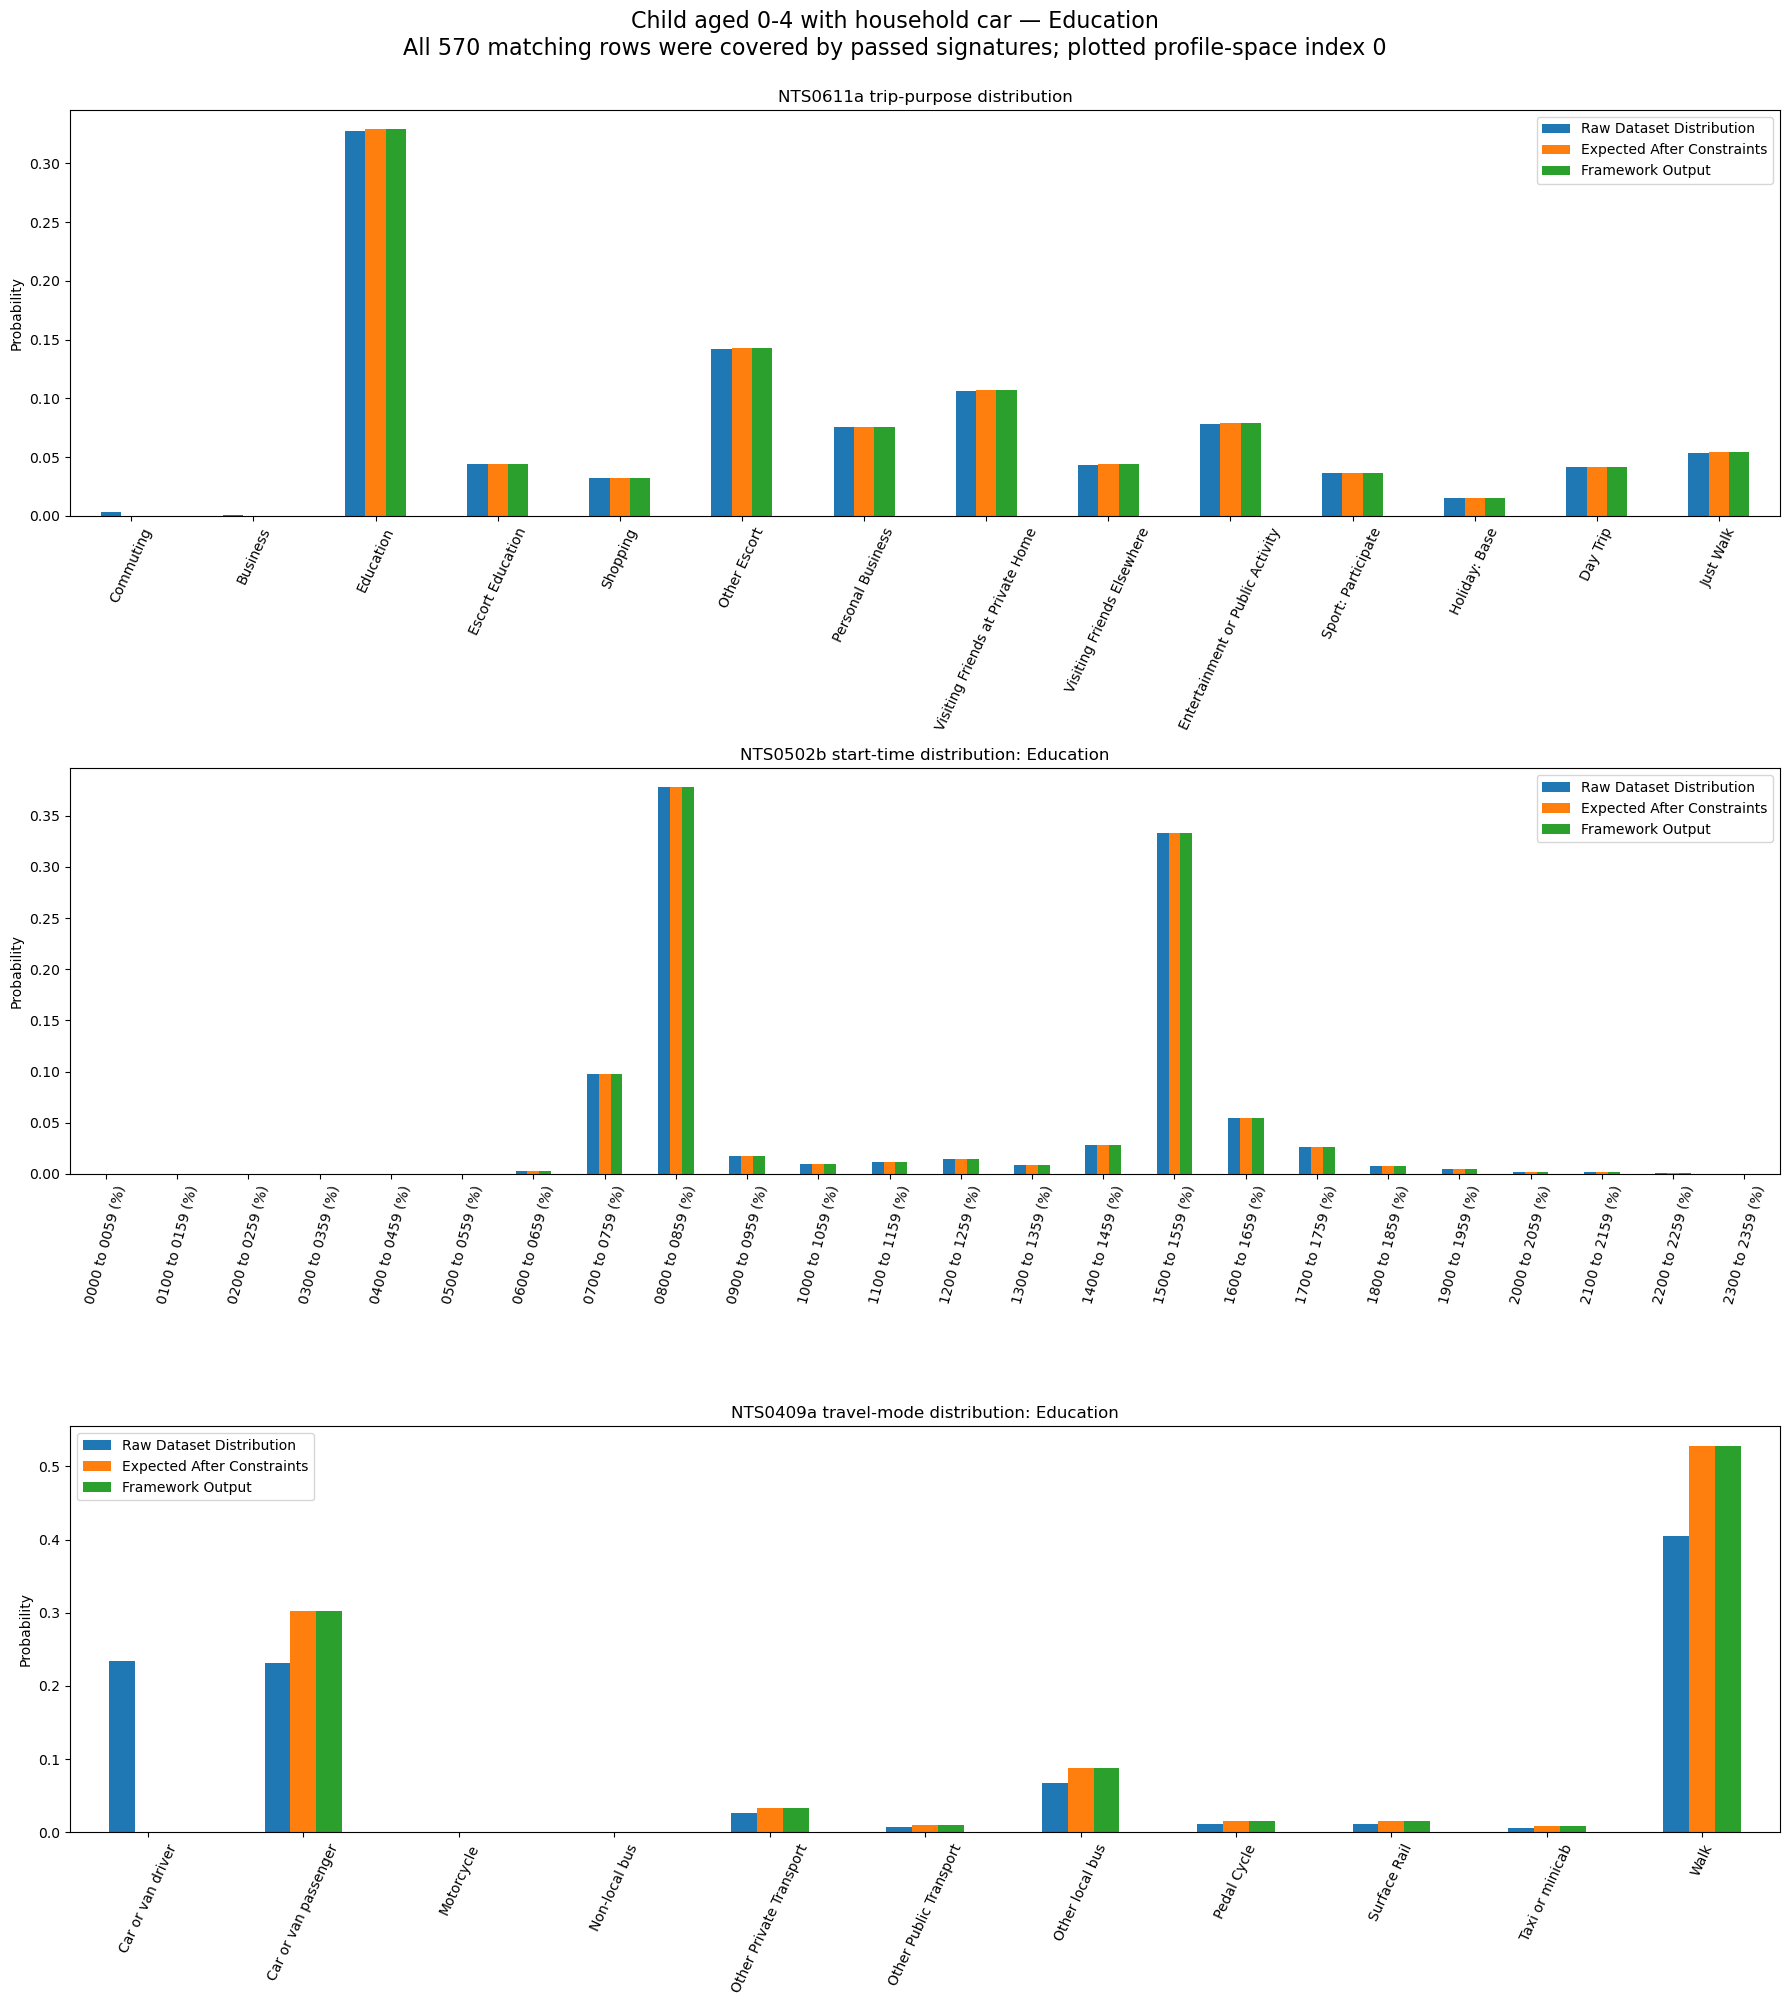

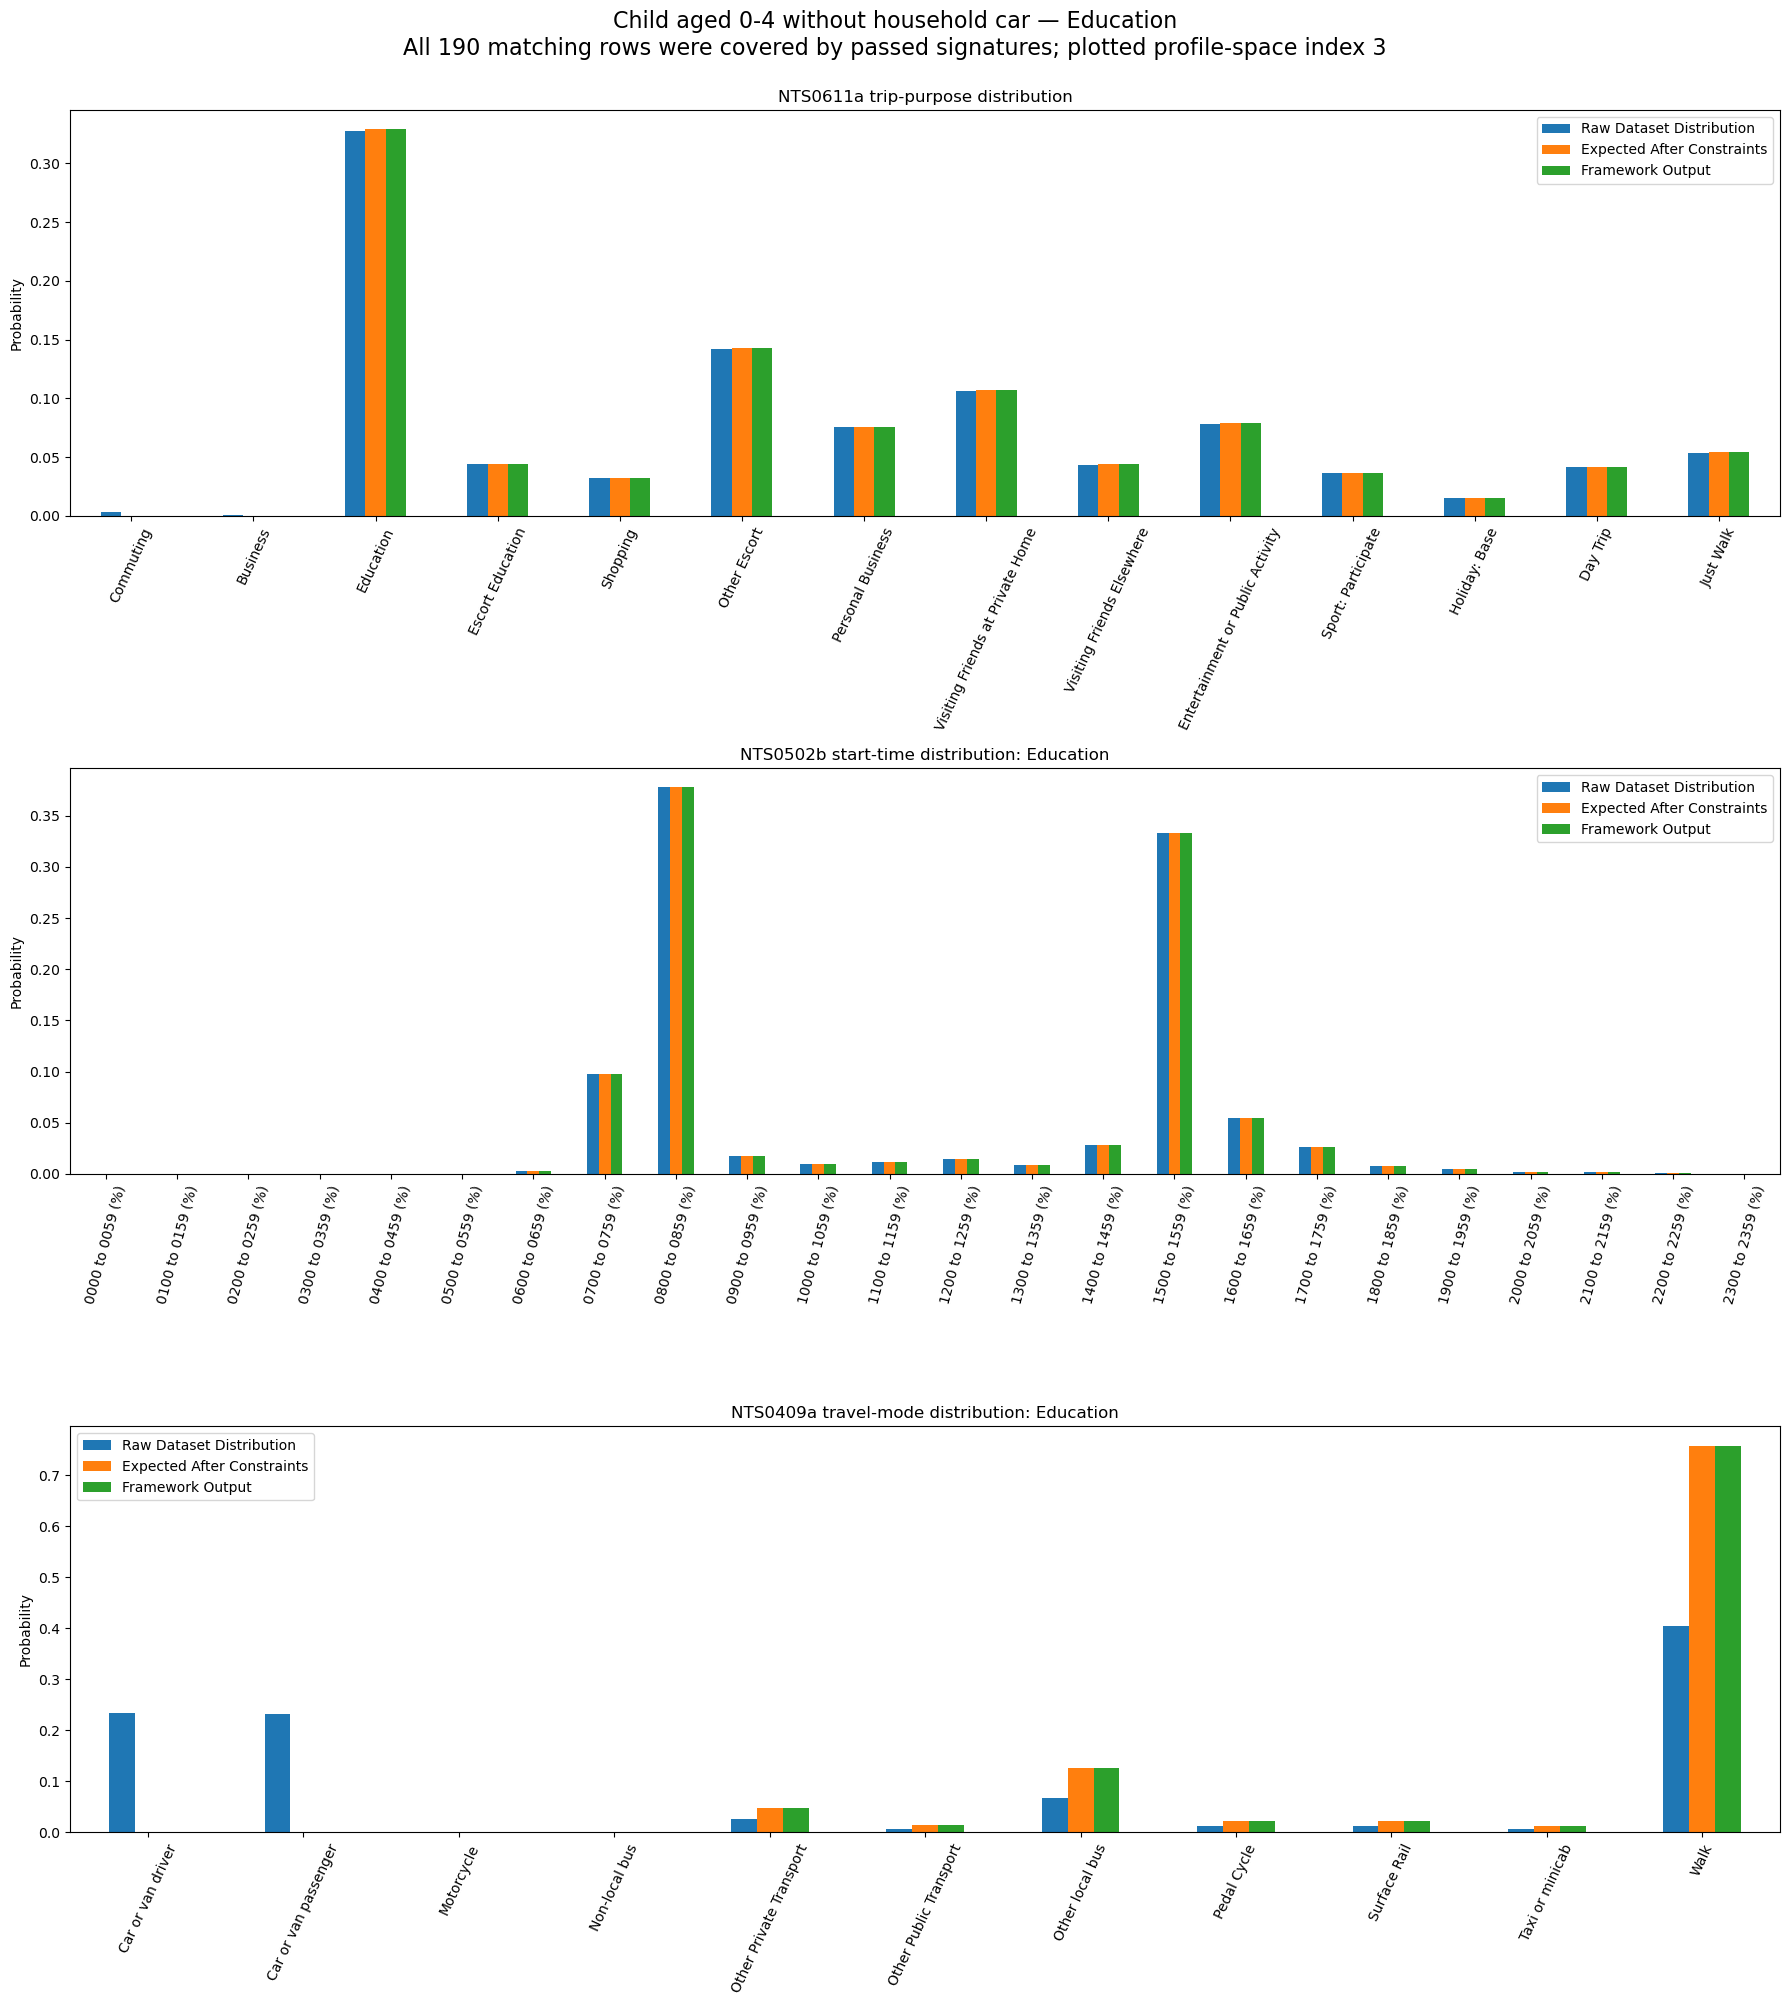

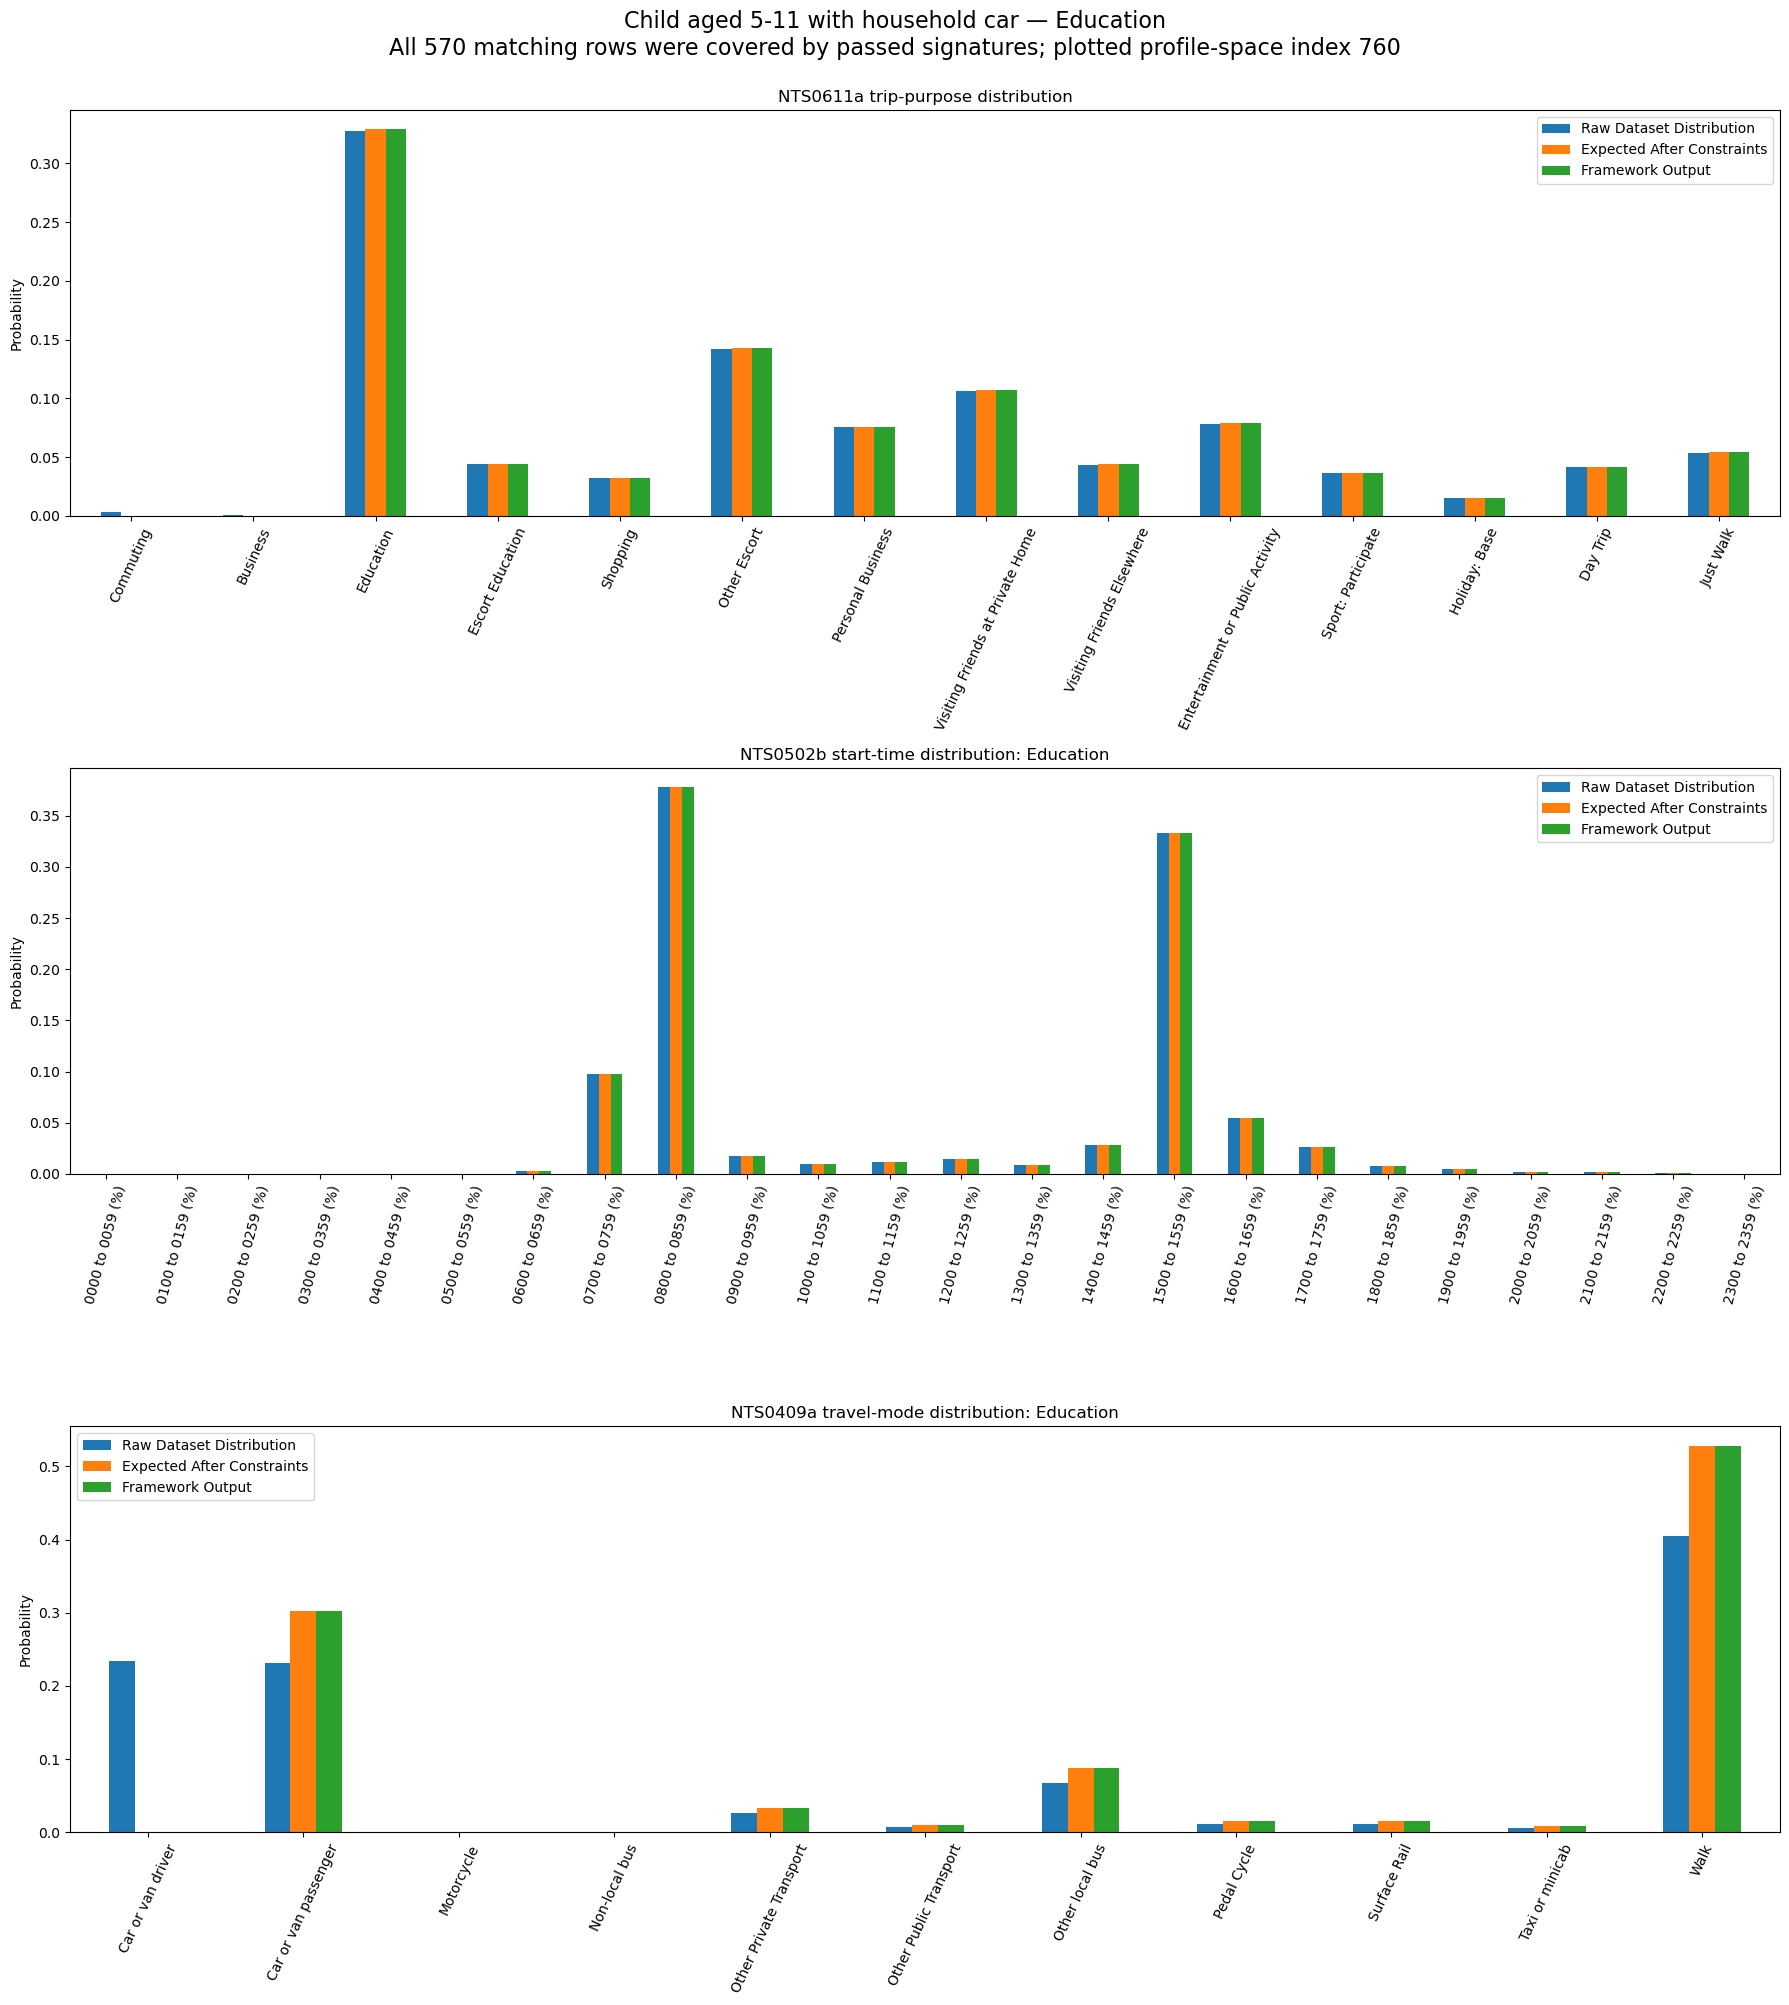

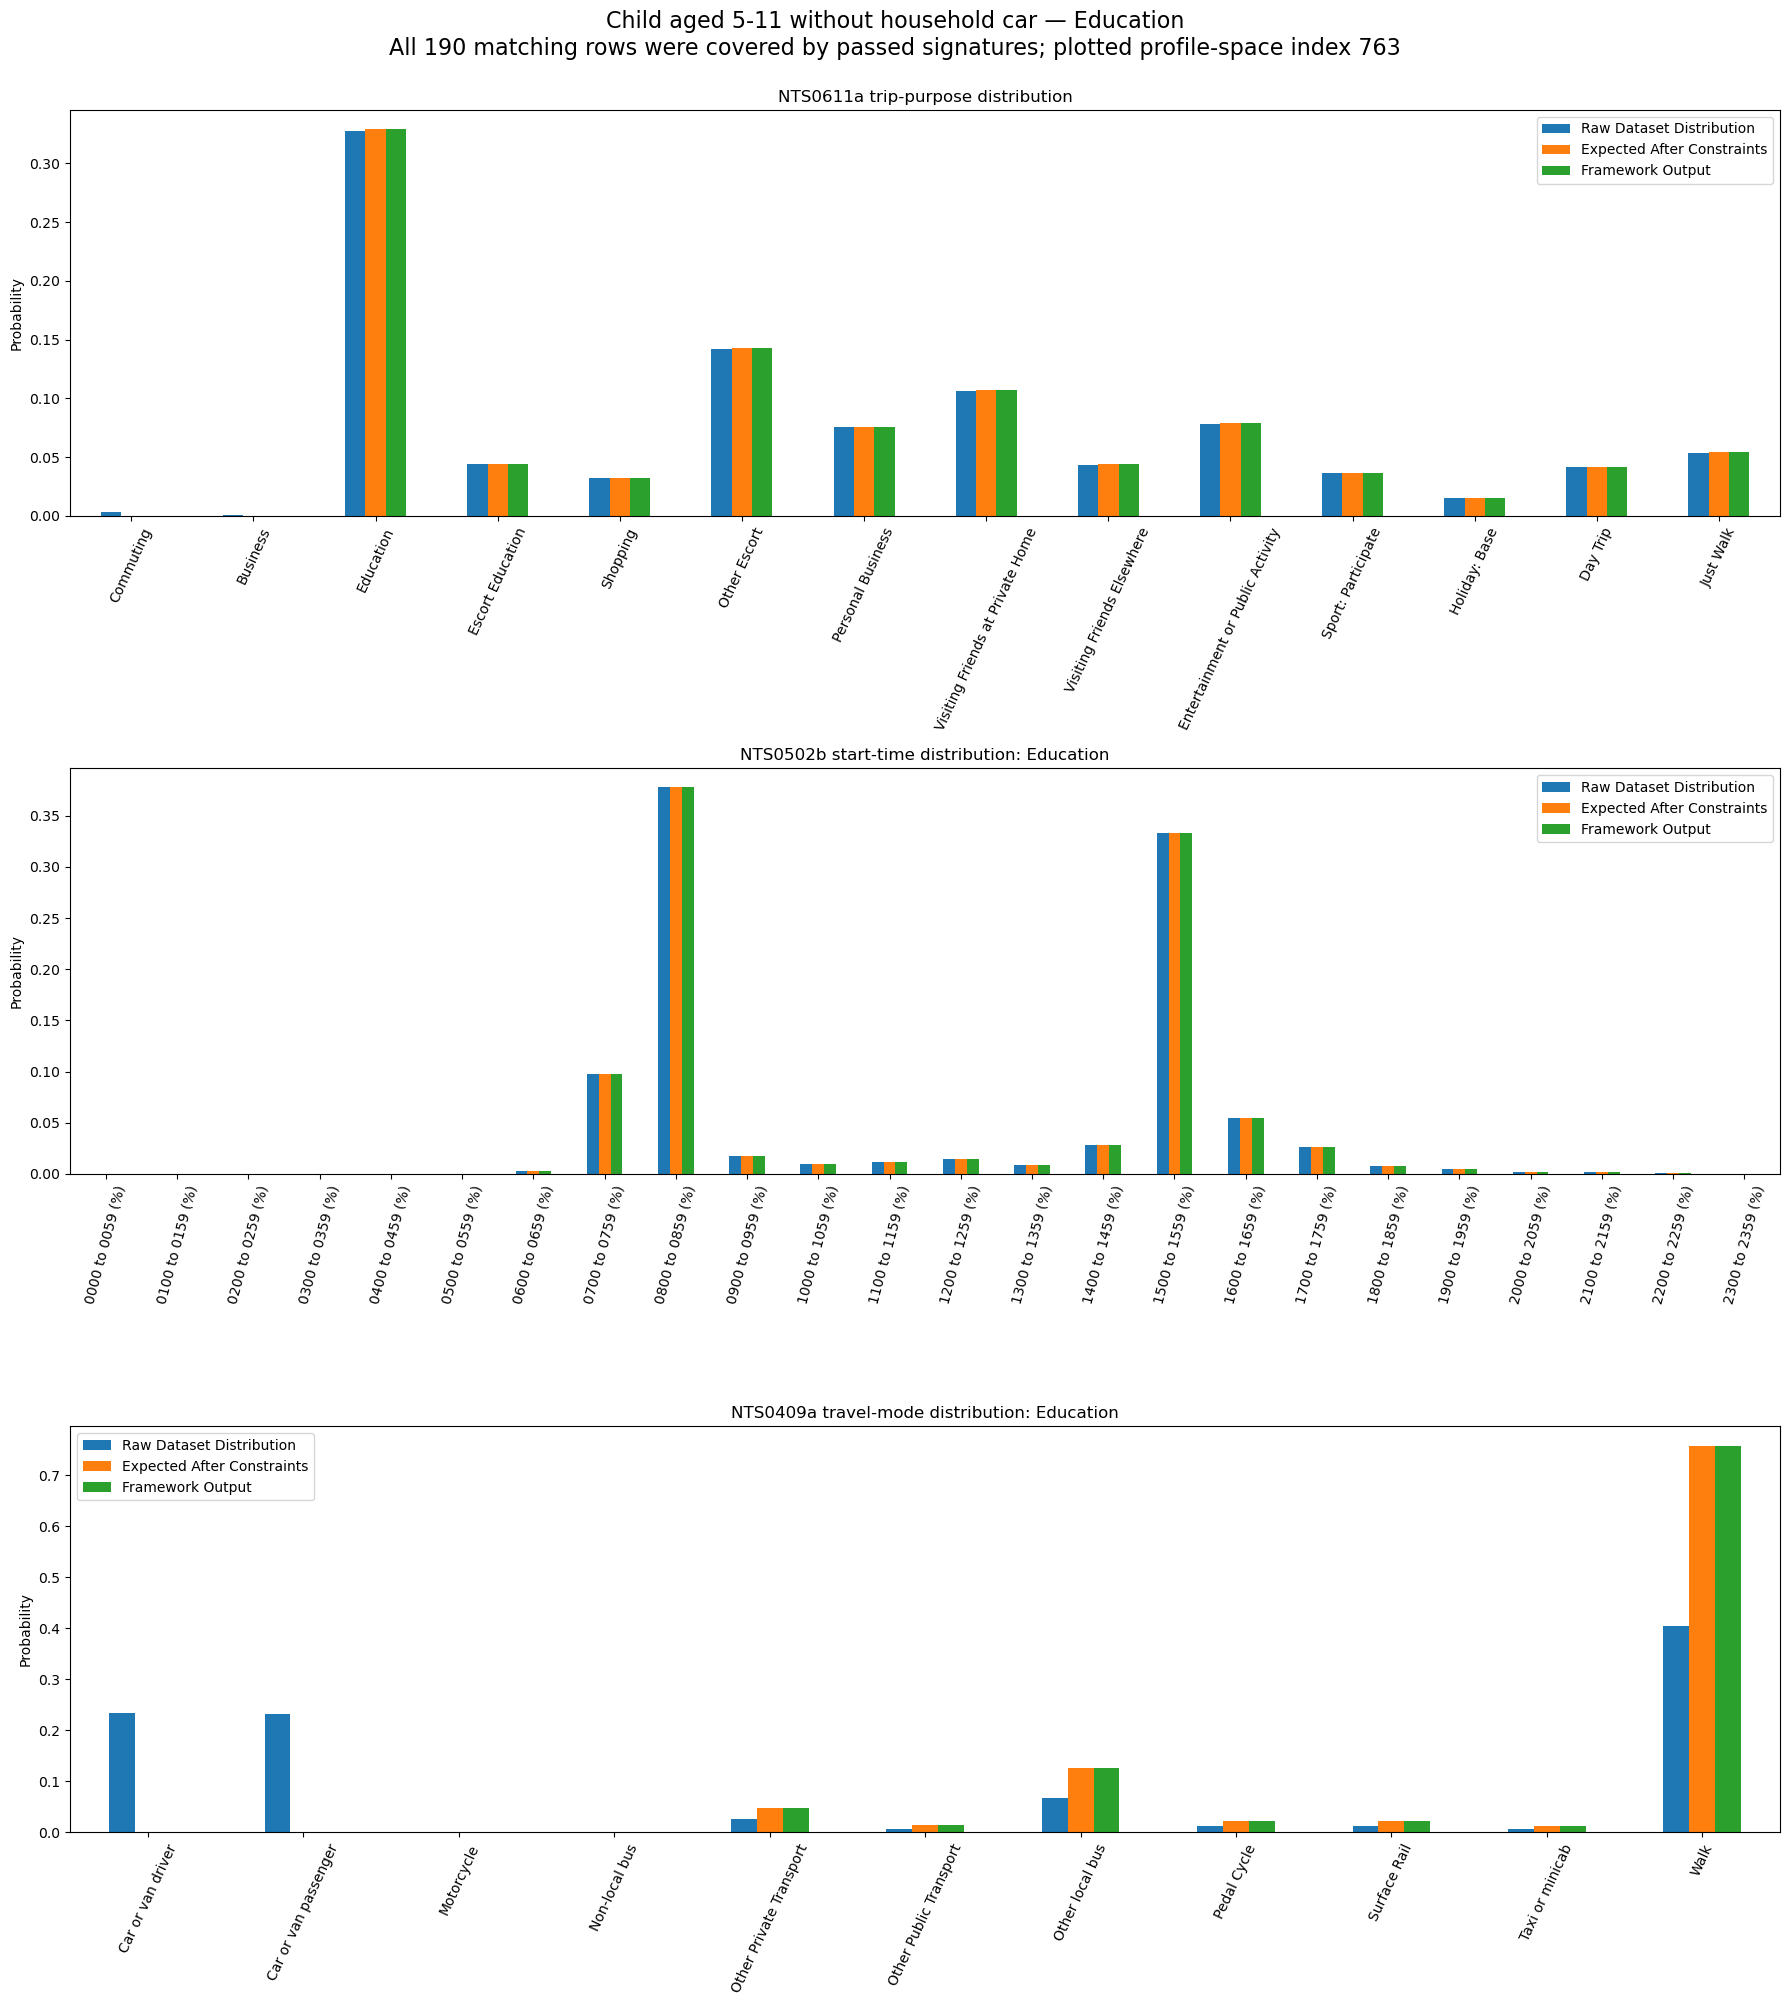

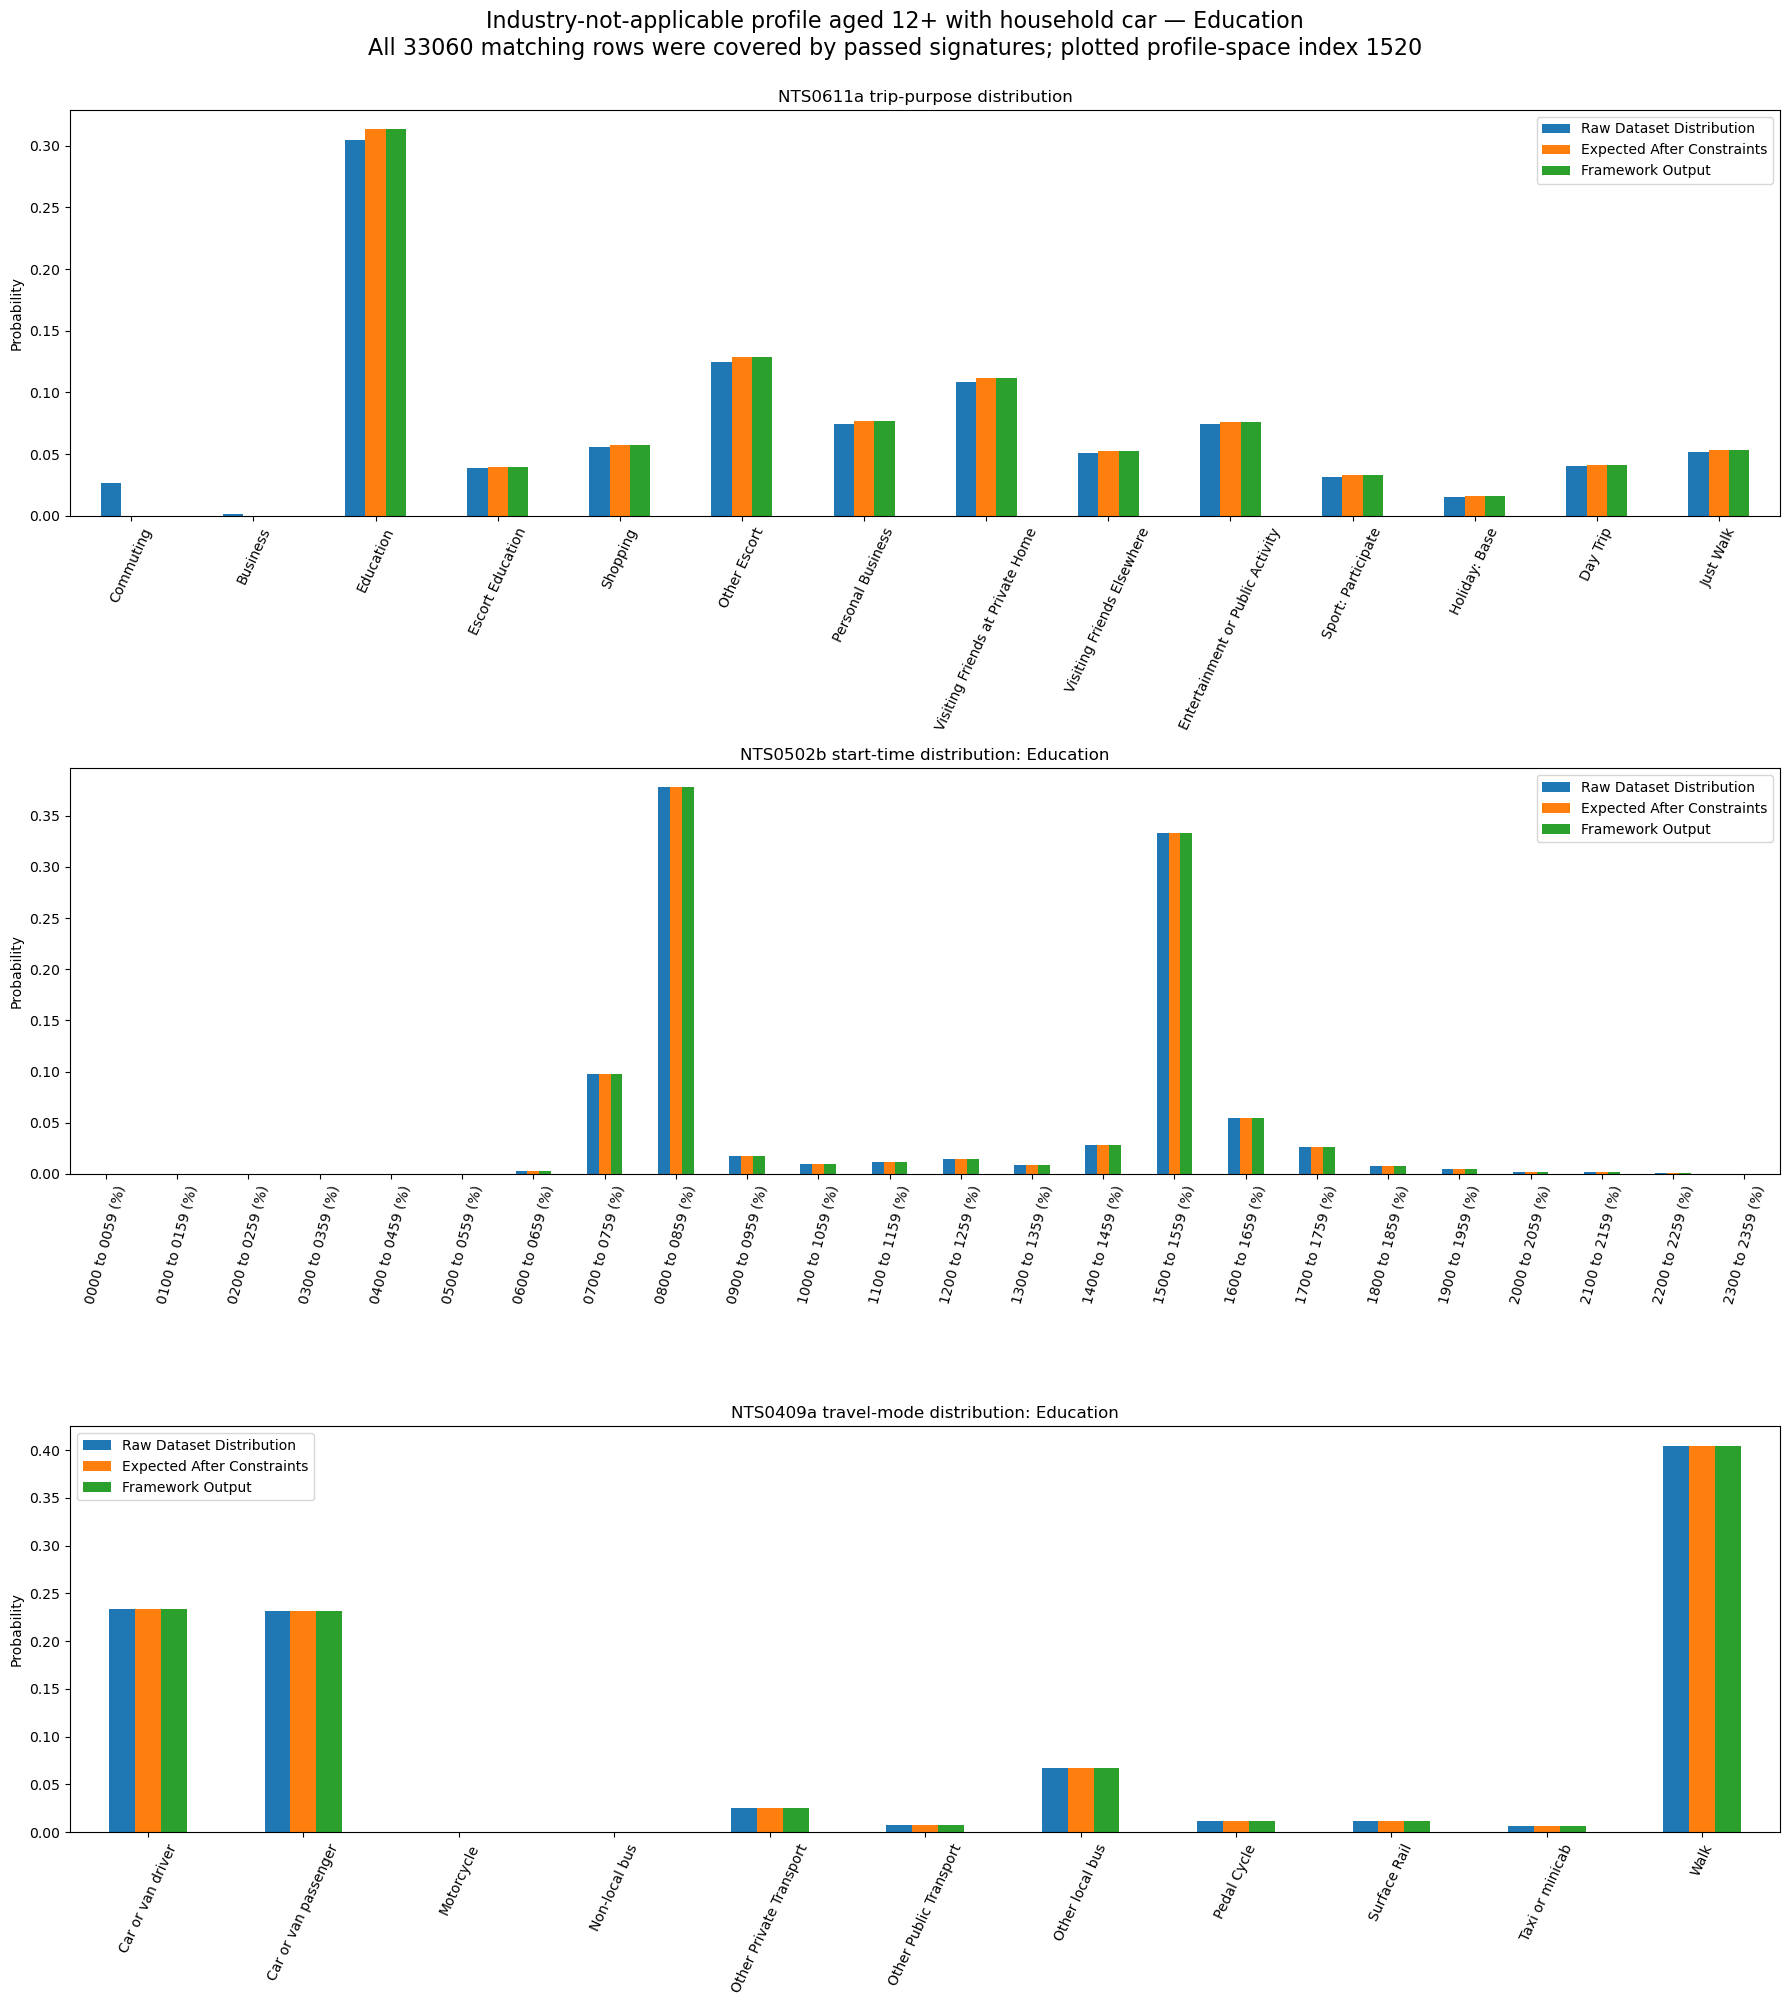

Displayed 5 representative plots and saved all 126 retained-purpose plots to c:\Users\user\OneDrive - University of Stirling\Desktop\dissertation\mobility-modelling-framework\output\validation\constraint_validation_plots


In [6]:
# AI Collaboration Record
# Tool: ChatGPT
# Purpose: Save every retained-purpose comparison plot after all validations
# pass while displaying only five representative figures in the notebook.
# Prompt:
# See AI_PROMPTS.md


def build_three_distribution_table(
    dataset_distribution,
    expected_after_constraints,
    framework_distribution,
):
    return pd.concat(
        [
            dataset_distribution.rename("Raw Dataset Distribution"),
            expected_after_constraints.reindex(
                dataset_distribution.index,
                fill_value=0.0,
            ).rename("Expected After Constraints"),
            framework_distribution.reindex(
                dataset_distribution.index,
                fill_value=0.0,
            ).rename("Framework Output"),
        ],
        axis=1,
    )


def build_all_purpose_constraint_figure(
    visualisation_name,
    purpose,
    plot_inputs,
    purpose_plot_inputs,
):
    figure, axes = plt.subplots(3, 1, figsize=(18, 20))

    build_three_distribution_table(
        plot_inputs["trip_dataset_distribution"],
        plot_inputs["trip_expected_after_constraints"],
        plot_inputs["framework_trip_distribution"],
    ).plot.bar(ax=axes[0])
    axes[0].set_title("NTS0611a trip-purpose distribution")
    axes[0].set_ylabel("Probability")
    axes[0].tick_params(axis="x", rotation=65)

    build_three_distribution_table(
        purpose_plot_inputs["temporal_dataset_distribution"],
        purpose_plot_inputs[
            "temporal_expected_after_constraints"
        ],
        purpose_plot_inputs["framework_temporal_distribution"],
    ).plot.bar(ax=axes[1])
    axes[1].set_title(
        f"NTS0502b start-time distribution: {purpose}"
    )
    axes[1].set_ylabel("Probability")
    axes[1].tick_params(axis="x", rotation=75)

    build_three_distribution_table(
        purpose_plot_inputs["mode_dataset_distribution"],
        purpose_plot_inputs["mode_expected_after_constraints"],
        purpose_plot_inputs["framework_mode_distribution"],
    ).plot.bar(ax=axes[2])
    axes[2].set_title(
        f"NTS0409a travel-mode distribution: {purpose}"
    )
    axes[2].set_ylabel("Probability")
    axes[2].tick_params(axis="x", rotation=65)

    visualisation_profile_count = expected_profile_counts[
        visualisation_name
    ]
    figure.suptitle(
        f"{visualisation_name} — {purpose}\n"
        f"All {visualisation_profile_count} matching rows were covered "
        "by passed signatures; plotted profile-space index "
        f"{plot_inputs['profile_space_index']}",
        fontsize=16,
        y=1.0,
    )
    figure.tight_layout()
    return figure


def make_plot_filename(text):
    return "".join(
        character.lower() if character.isalnum() else "_"
        for character in text
    ).strip("_")


assert total_profiles_failed == 0, (
    "Plots are generated only after every constrained row is covered "
    "by a passed signature."
)
assert len(representative_plot_inputs) == len(
    constraint_visualisations
)

MAX_DISPLAYED_PLOTS = 5
constraint_plot_directory.mkdir(parents=True, exist_ok=True)
all_purpose_plot_paths = {}
displayed_visualisations = set()

for visualisation in constraint_visualisations:
    visualisation_name = visualisation["visualisation"]
    plot_inputs = representative_plot_inputs[visualisation_name]

    for purpose, purpose_plot_inputs in plot_inputs[
        "purpose_validation_results"
    ].items():
        figure = build_all_purpose_constraint_figure(
            visualisation_name,
            purpose,
            plot_inputs,
            purpose_plot_inputs,
        )
        plot_path = constraint_plot_directory / (
            make_plot_filename(visualisation_name)
            + "__"
            + make_plot_filename(purpose)
            + ".png"
        )
        figure.savefig(plot_path, dpi=300, bbox_inches="tight")
        should_display = (
            len(displayed_visualisations) < MAX_DISPLAYED_PLOTS
            and visualisation_name not in displayed_visualisations
        )
        if should_display:
            plt.show()
            displayed_visualisations.add(visualisation_name)
        plt.close(figure)
        all_purpose_plot_paths[
            (visualisation_name, purpose)
        ] = plot_path

expected_plot_count = sum(
    len(plot_inputs["purpose_validation_results"])
    for plot_inputs in representative_plot_inputs.values()
)
assert len(all_purpose_plot_paths) == expected_plot_count
assert len(displayed_visualisations) == min(
    MAX_DISPLAYED_PLOTS,
    len(constraint_visualisations),
)

print(
    f"Displayed {len(displayed_visualisations)} representative plots "
    f"and saved all {len(all_purpose_plot_paths)} retained-purpose "
    f"plots to {constraint_plot_directory}"
)


### Interpretation

A complete PASS establishes implementation correctness and distribution consistency for the demographic constraints currently implemented in the project.

- The validation input is the already constrained representative profile space; this notebook does not create or constrain that profile space.
- Every imported constrained row satisfies the checked age, employment and household consistency rules and belongs to exactly one of the ten behavioural cases.
- Every row is mapped to a behavioural signature defined by its case, age and gender. The framework is executed once per unique signature, and the passed result is mapped back to every row represented by that signature.
- Raw NTS0611 remains visible and unchanged as the source baseline, including non-zero child `Commuting` and `Business` probabilities.
- `Industry = Does not apply` removes `Commuting` and `Business` only in the expected constrained and framework-output distributions.
- Work from home removes `Commuting` while retaining `Business`.
- Young-age and no-household-car rules remove exactly the specified NTS0409 modes, including their combined effect.
- NTS0502 is preserved for every retained trip purpose.
- All case-purpose plots are generated only after the complete numerical validation passes.

The signature cache changes computational efficiency only. It does not sample or omit constrained rows: all rows receive a validation result through their exact model-relevant signature. This validates the implemented transformations, not the real-world completeness of the rules themselves.


### 7. WFH age–gender coverage visualisation

This section summarises the exhaustive validation coverage of the two
home-working cases. The heatmap visualises the independently expected
NTS0611 trip-purpose distributions for all eligible age–gender signatures
after removing Commuting and renormalising the remaining probabilities.

Household car availability is not separated in the heatmap because it
affects the travel-mode distribution rather than the trip-purpose
distribution. Both household-car conditions were nevertheless validated
separately.

### 7. WFH trip-purpose distributions before and after constraints

The following figures directly compare the original NTS0611 trip-purpose
distribution with the expected distribution after removing Commuting and
renormalising the remaining probabilities. A separate comparison is shown
for every validated age–gender signature.

Household-car availability is not separated because it does not alter the
trip-purpose distribution. Both household-car conditions were nevertheless
validated separately in the preceding numerical validation.

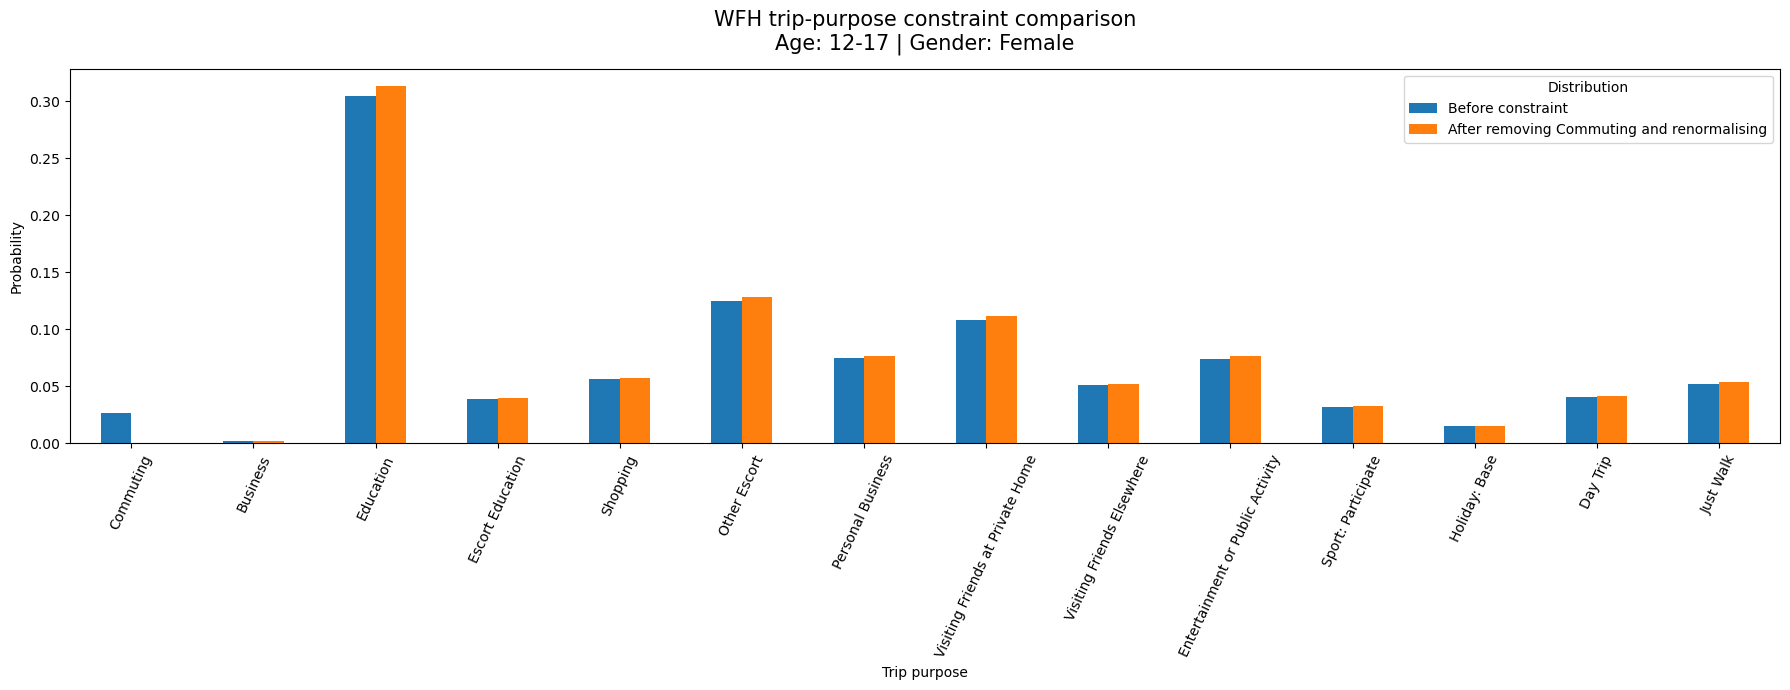

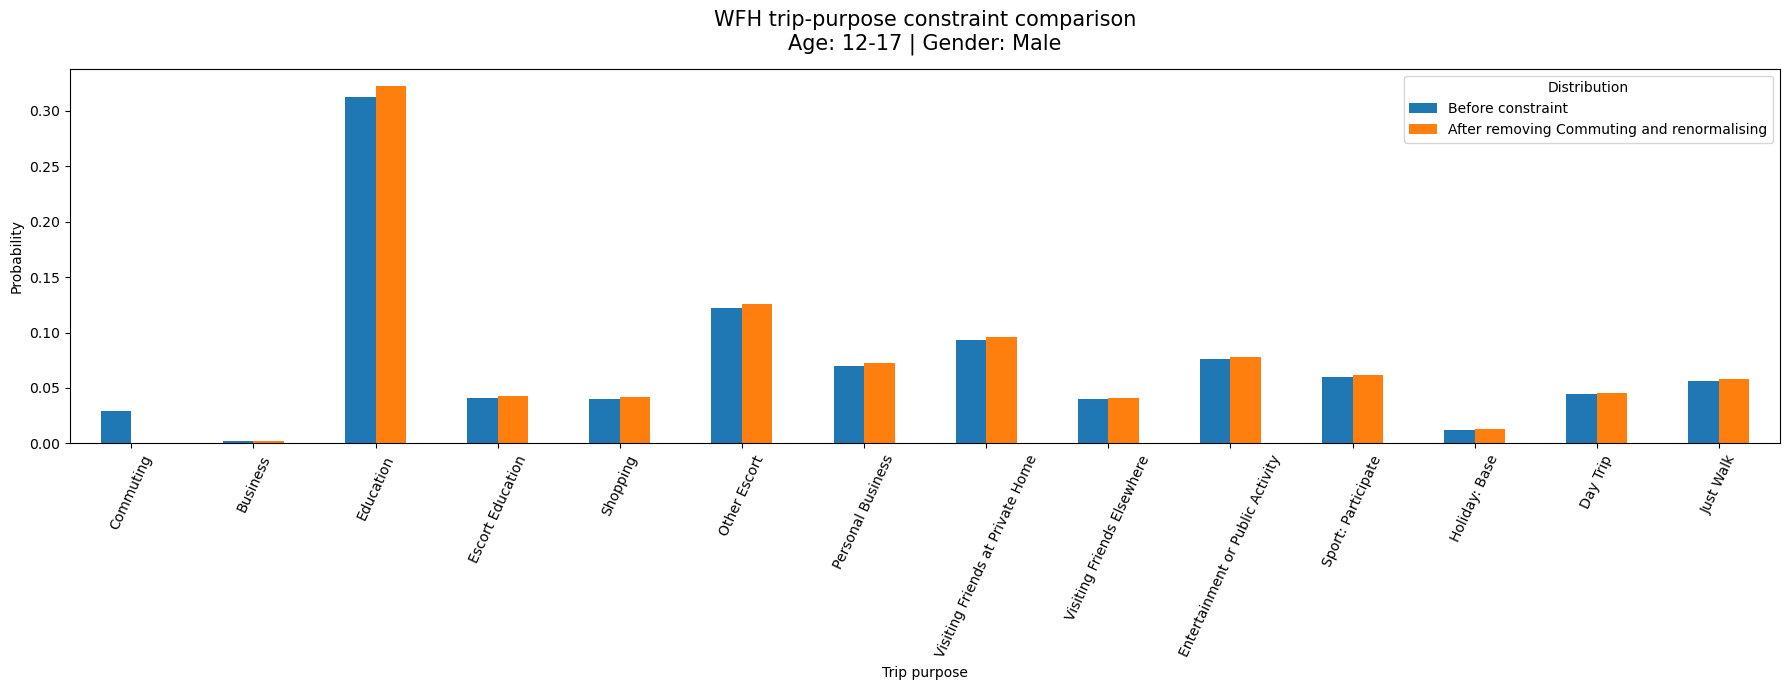

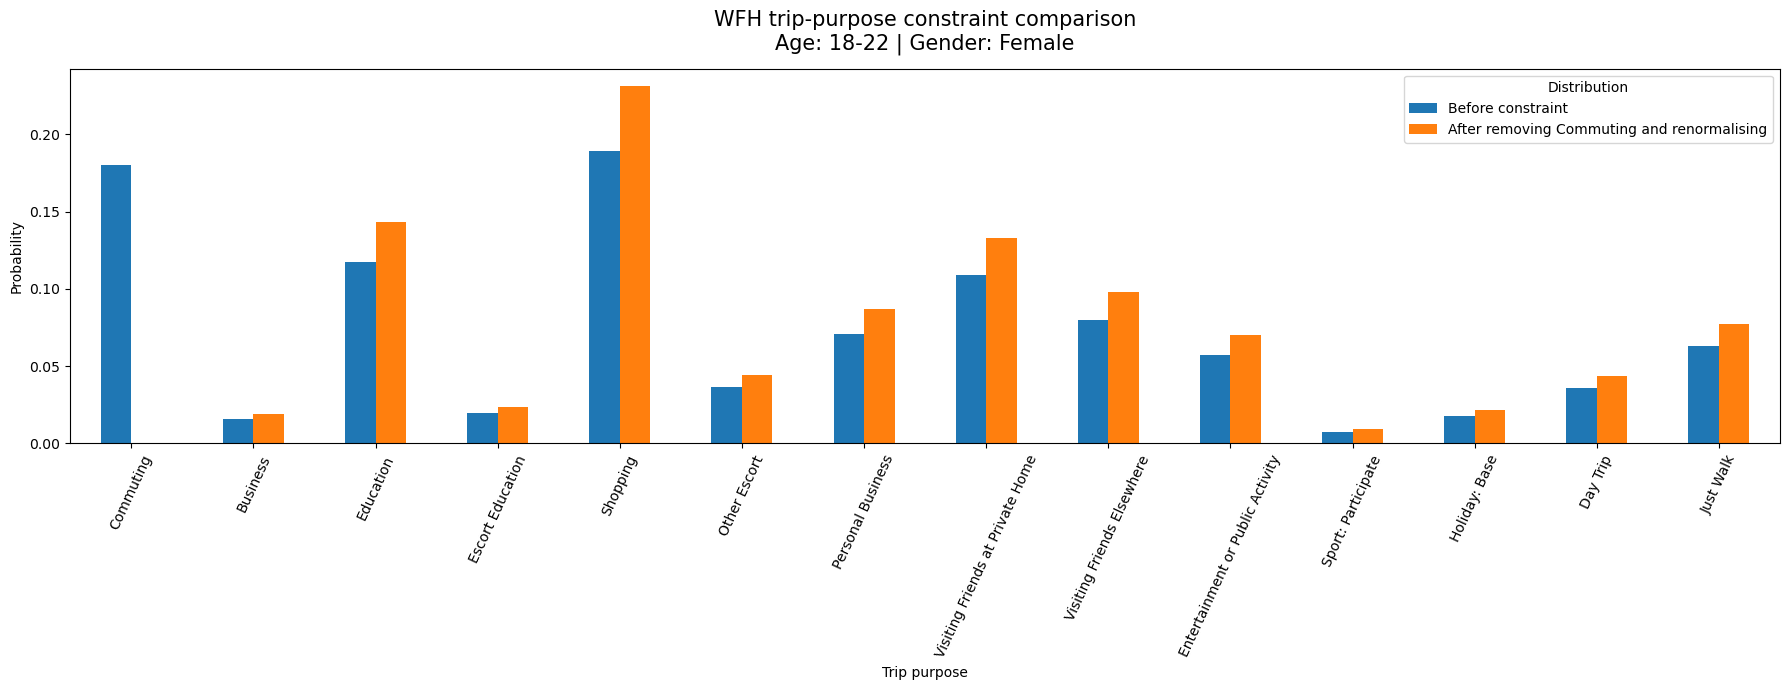

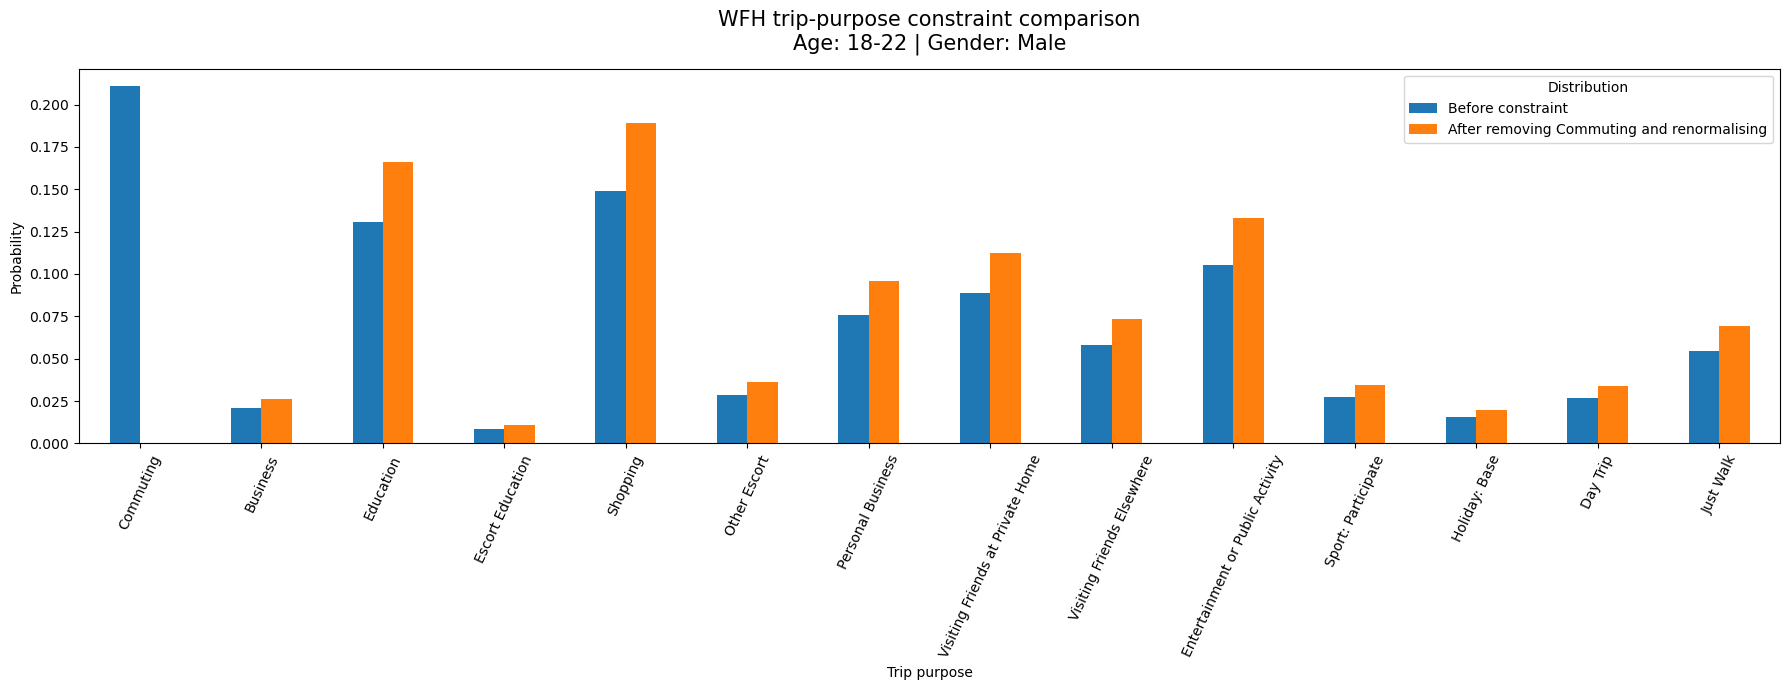

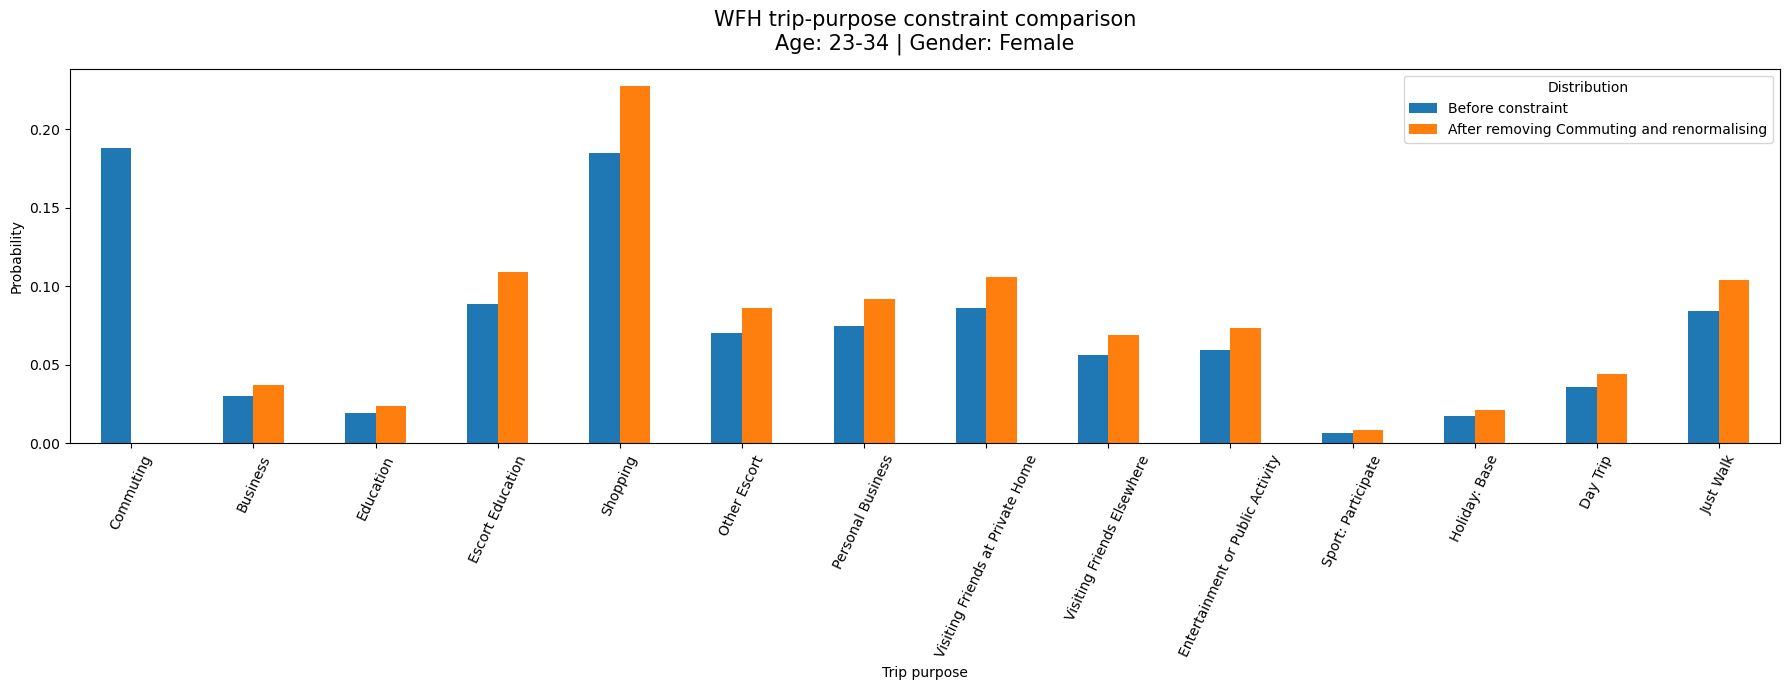

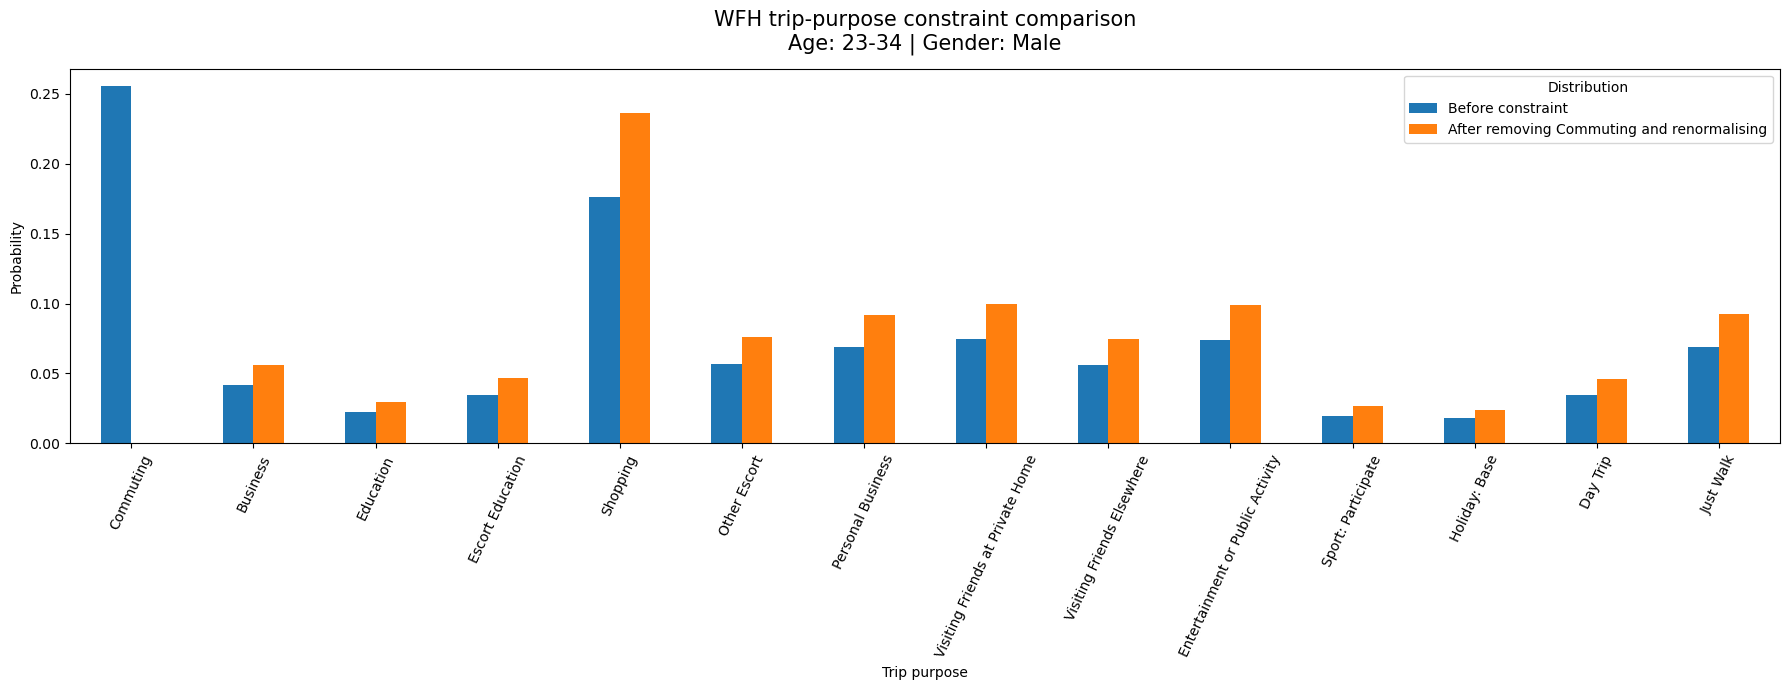

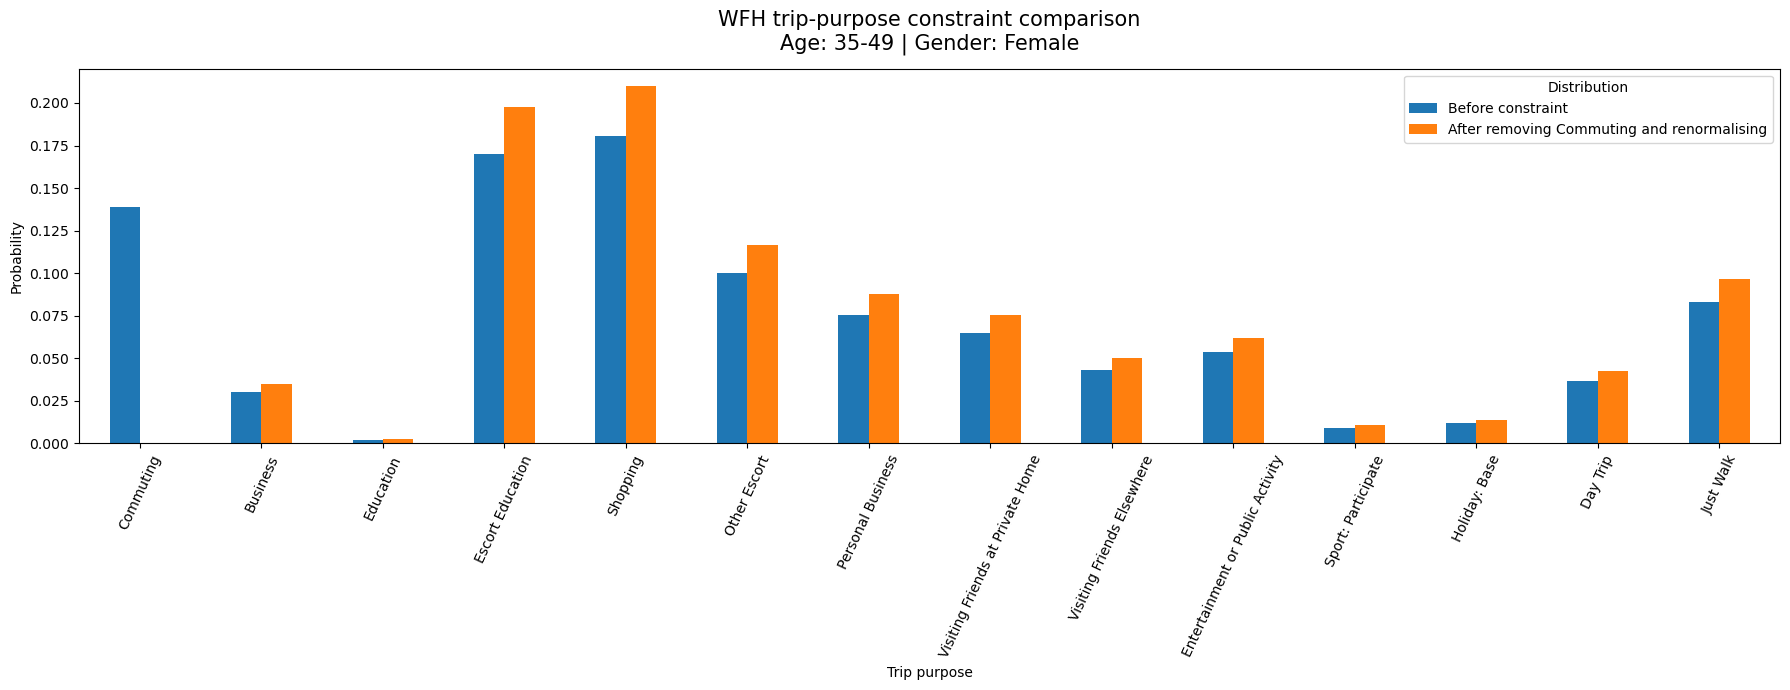

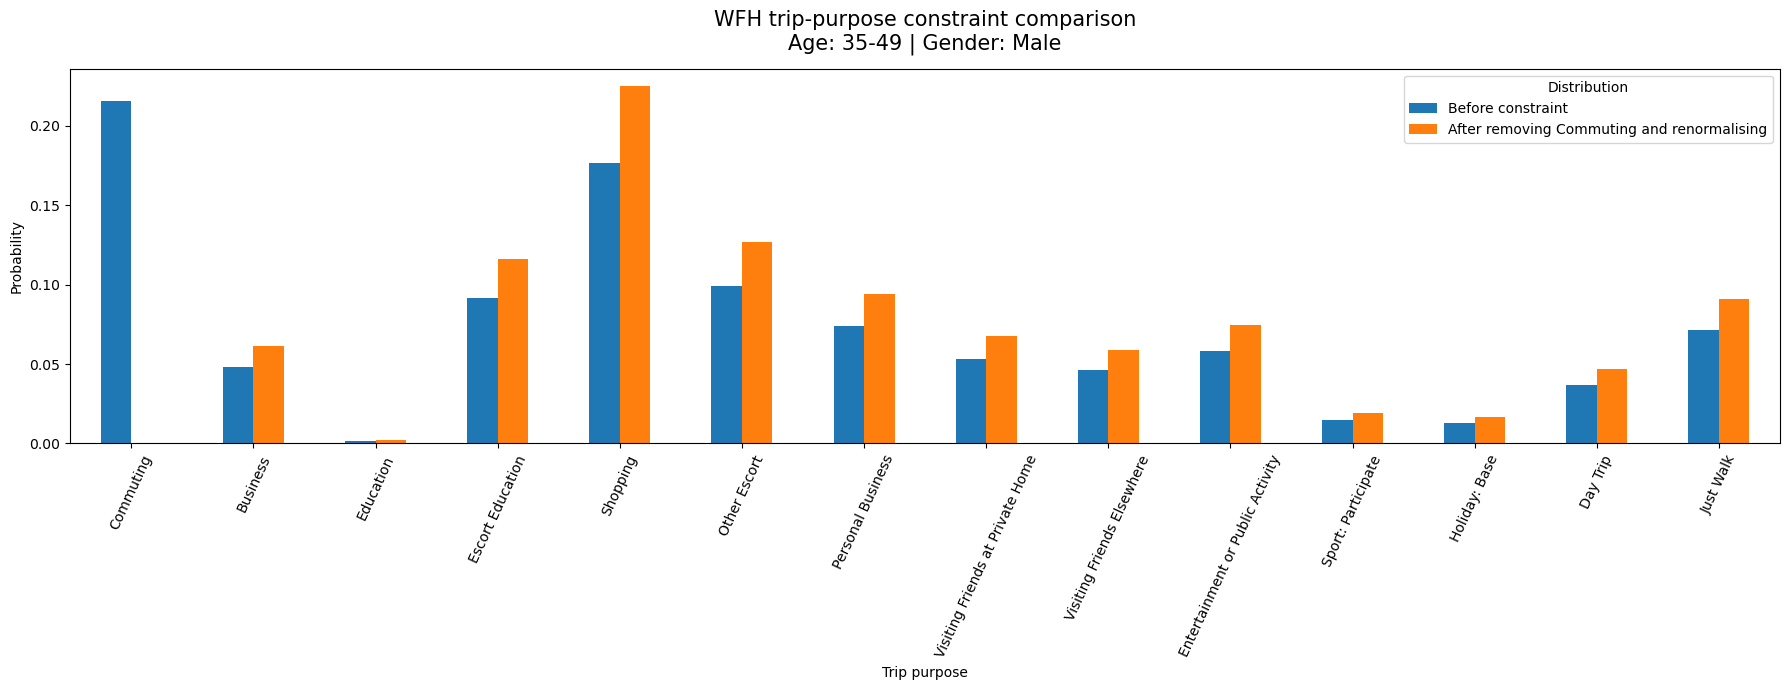

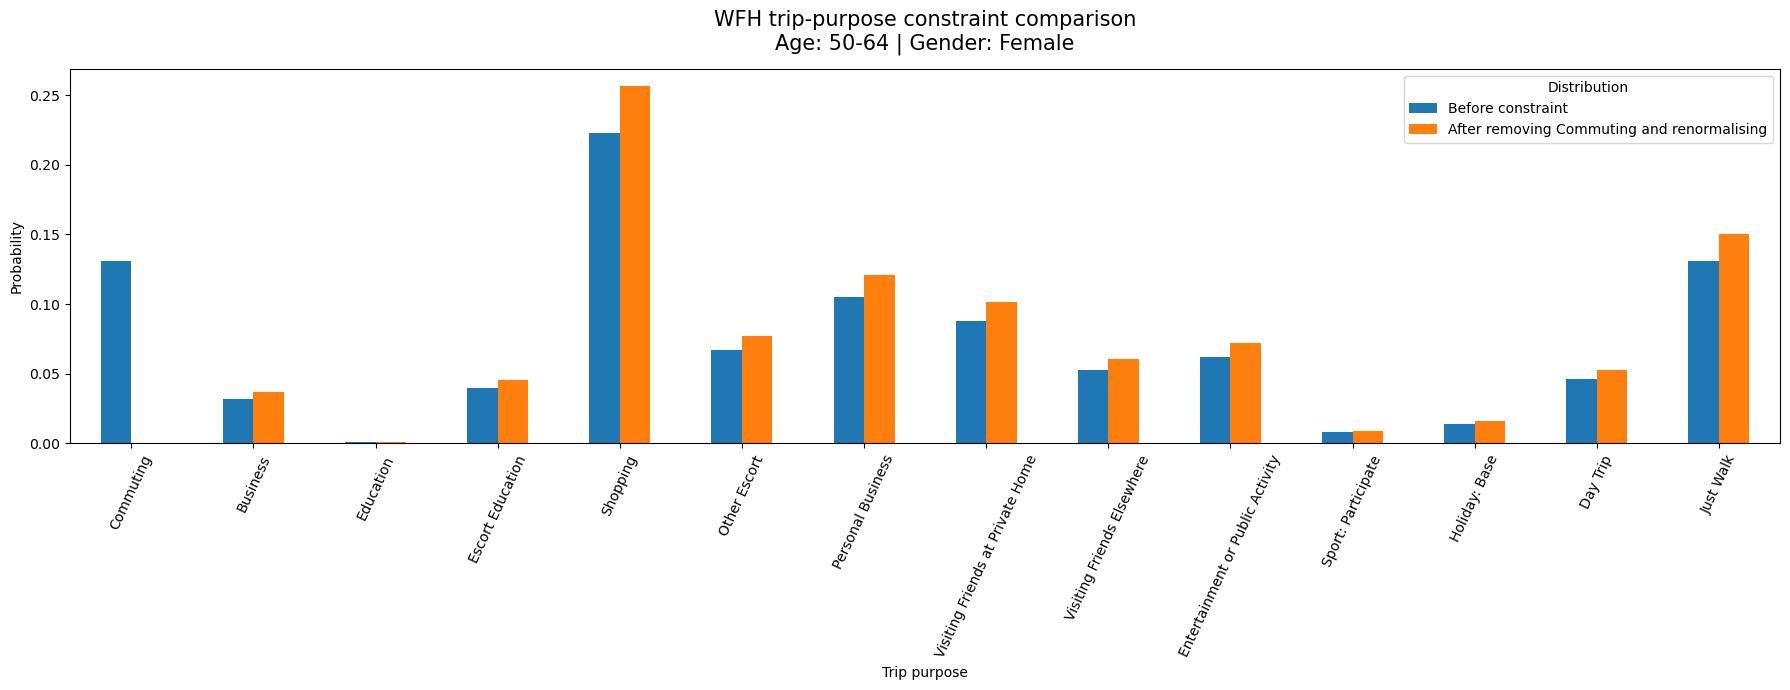

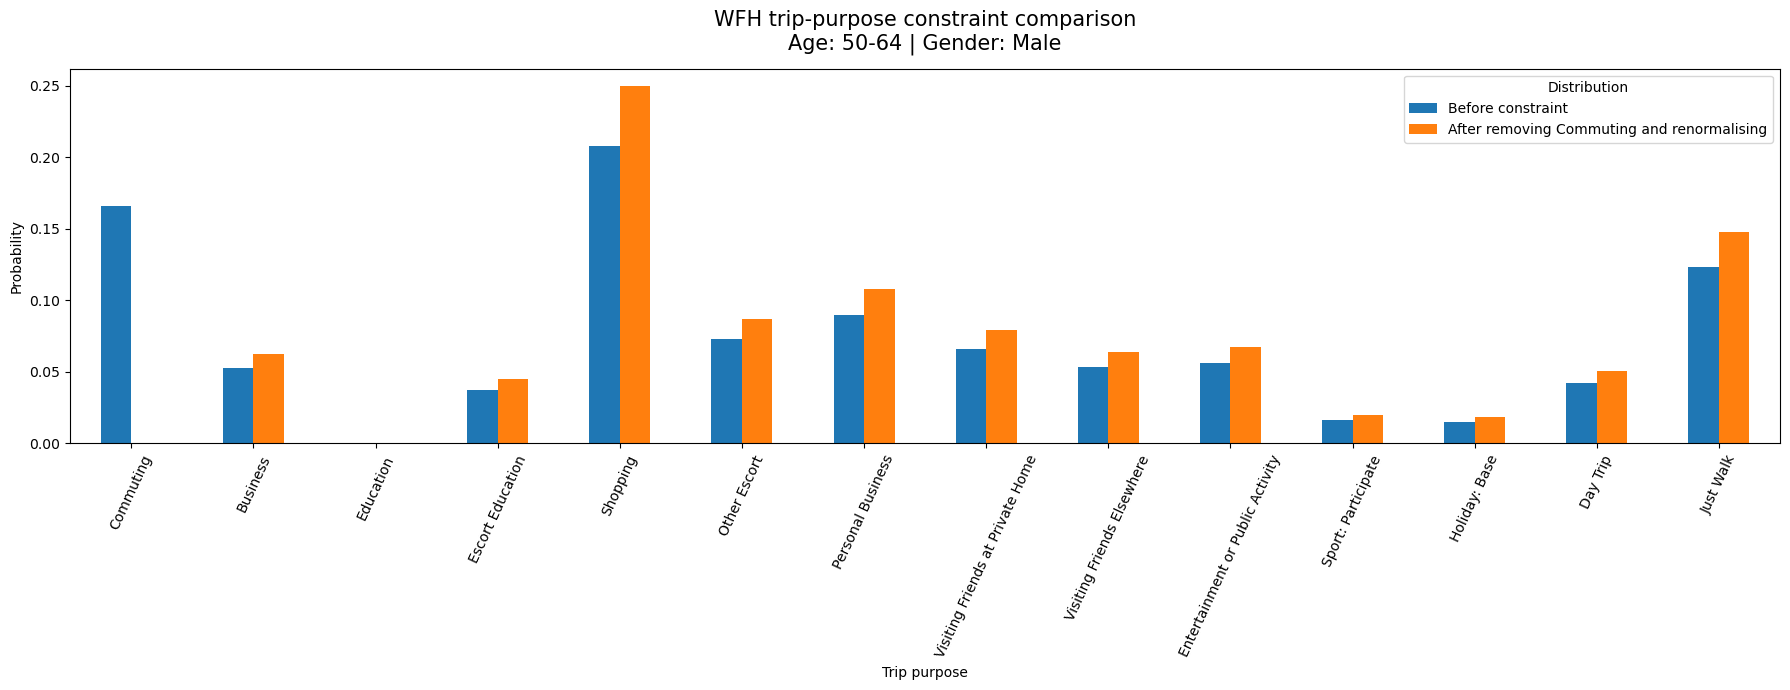

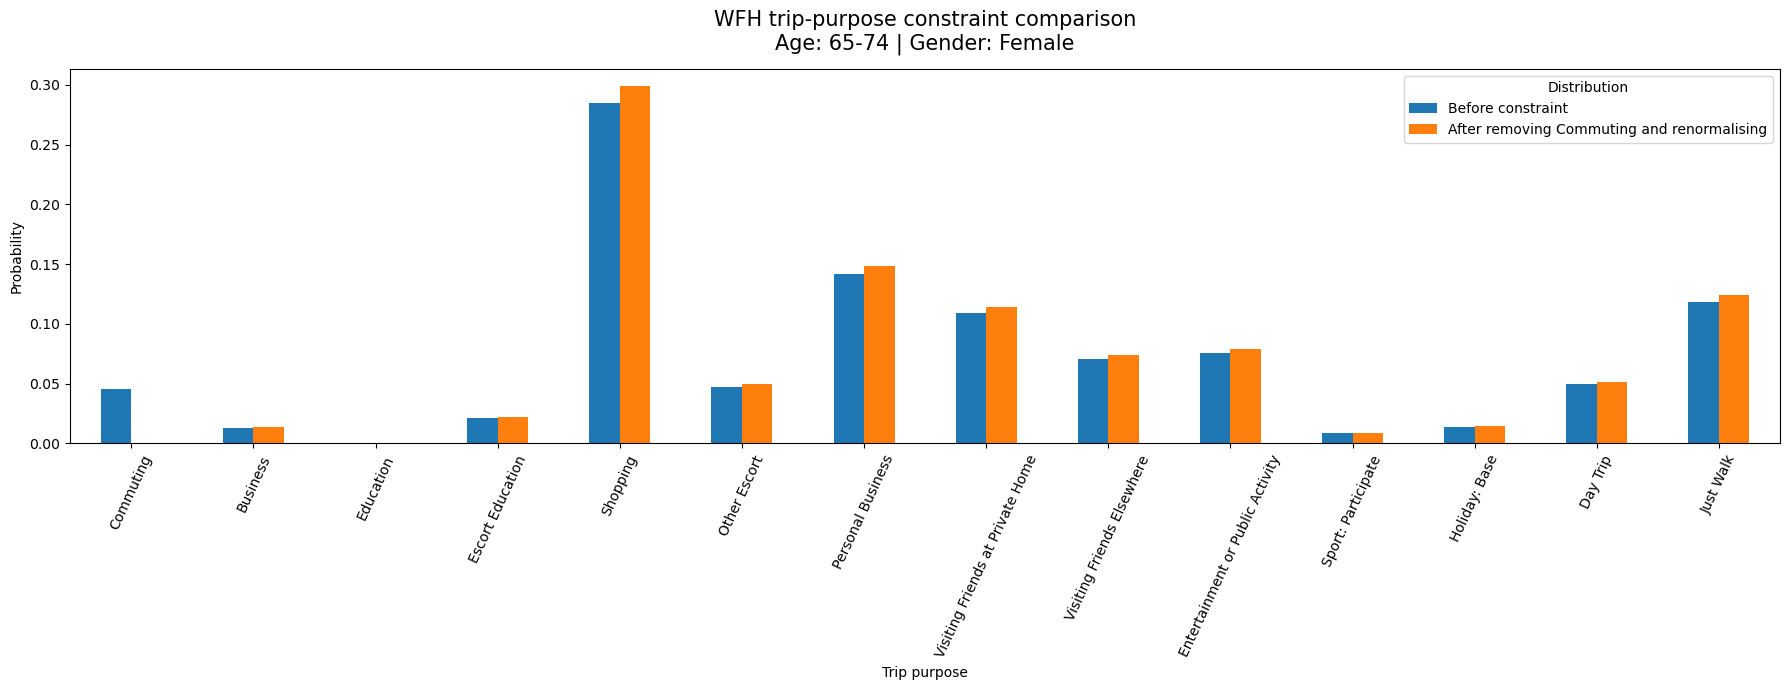

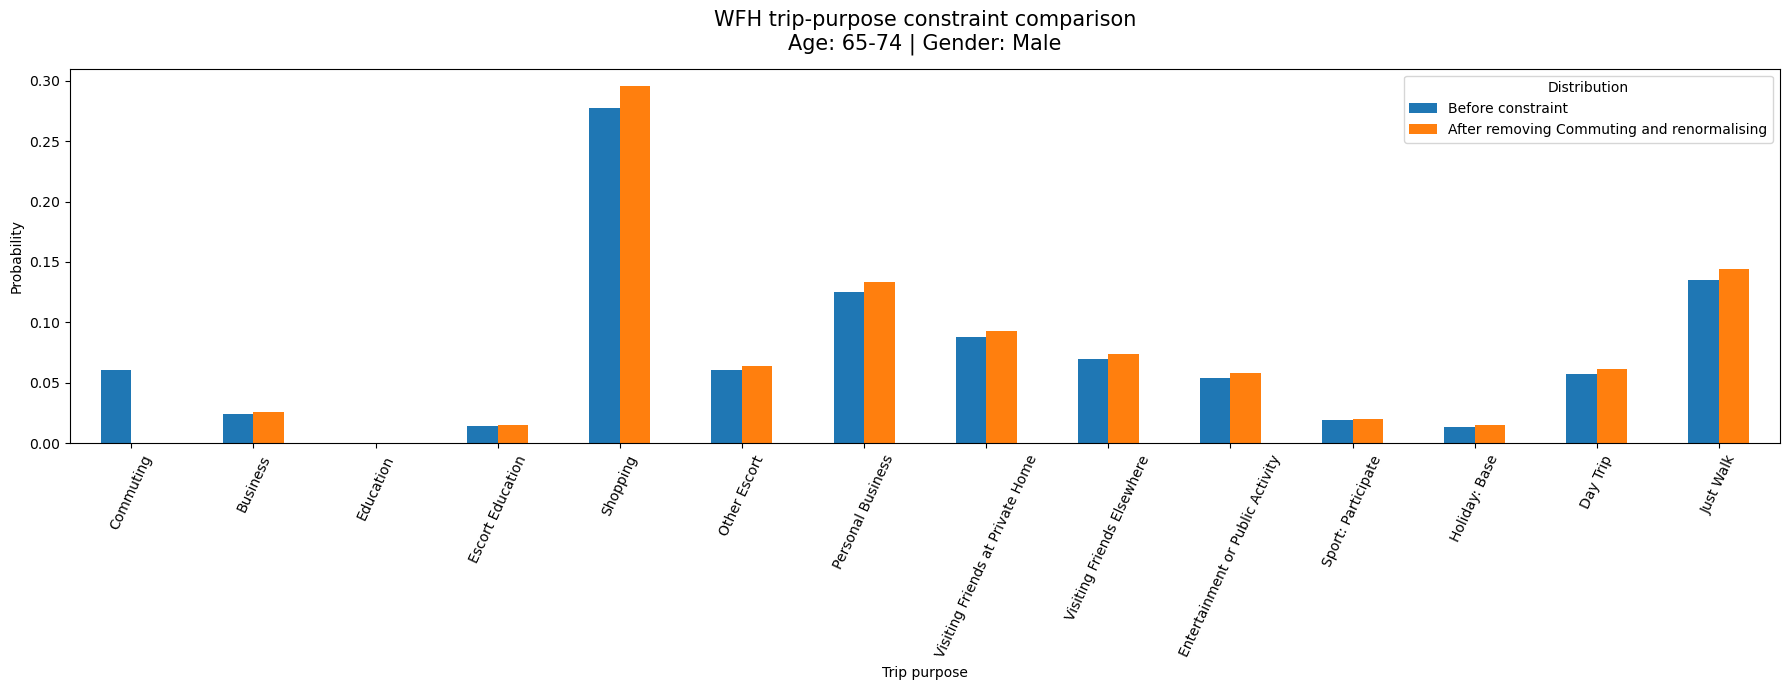

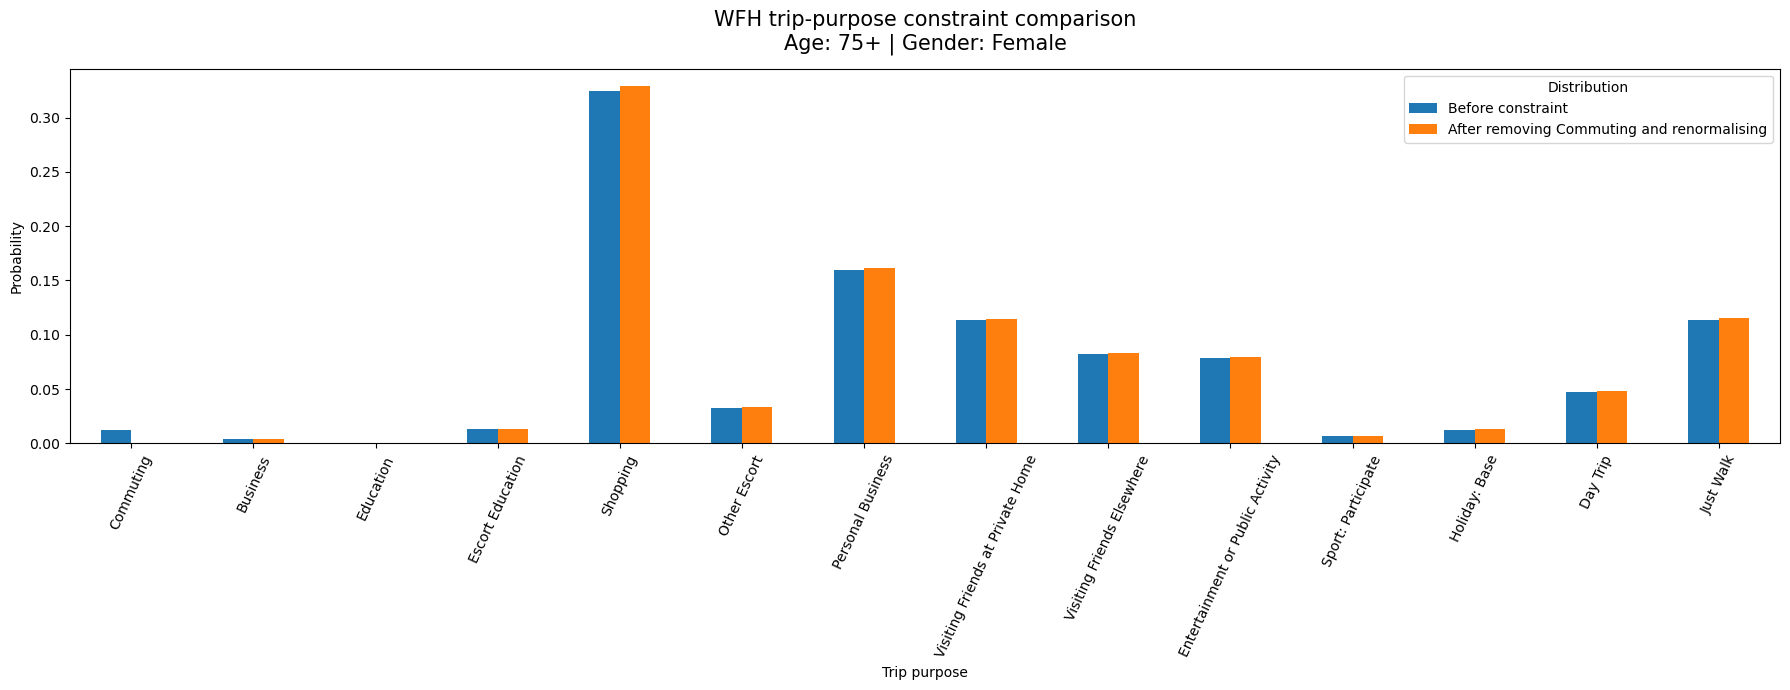

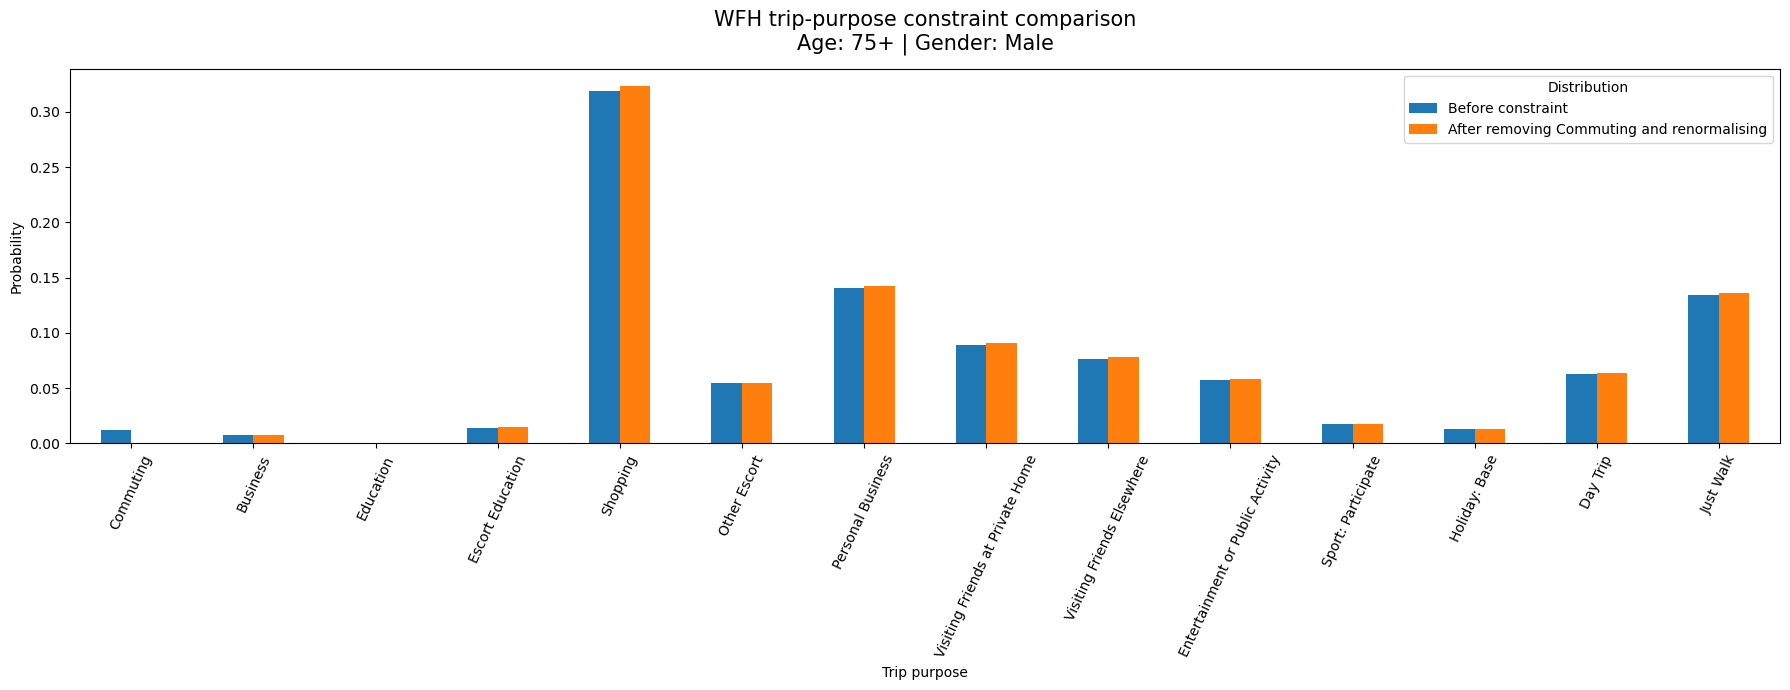

PASS: Generated direct before-and-after WFH trip-purpose plots for all 14 validated Age × Gender signatures.
Plots saved to: c:\Users\user\OneDrive - University of Stirling\Desktop\dissertation\mobility-modelling-framework\output\validation\constraint_validation_plots\wfh_before_after


In [7]:
# AI Collaboration Record
# Tool: ChatGPT
# Purpose: Visualise the WFH trip-purpose distribution before and
# after removing Commuting for every validated age-gender signature.
# Prompt:
# See AI_PROMPTS.md


WFH_CASES = [
    "Work from home profile with household car",
    "Work from home profile without household car",
]


# ---------------------------------------------------------
# 1. Identify all validated WFH age-gender signatures
# ---------------------------------------------------------

wfh_signature_details = signature_validation_details.loc[
    signature_validation_details["visualisation"].isin(WFH_CASES)
].copy()

assert set(wfh_signature_details["visualisation"]) == set(WFH_CASES), (
    "One or more expected WFH cases are missing."
)

assert wfh_signature_details["Result"].eq("PASS").all(), (
    "One or more WFH signatures failed validation."
)

assert wfh_signature_details[
    "Purpose Removals Correct"
].all(), (
    "Commuting was not correctly removed for every WFH signature."
)

assert wfh_signature_details[
    "WFH Business Retained"
].all(), (
    "Business was not retained for every WFH signature."
)


# The two household-car cases contain the same Age × Gender
# combinations, so retain one copy of each combination.

wfh_age_gender_signatures = (
    wfh_signature_details[
        ["Age", "Gender"]
    ]
    .drop_duplicates()
    .copy()
)

assert len(wfh_age_gender_signatures) == 14, (
    "Expected 14 unique WFH age-gender signatures."
)


# Preserve the Age and Gender ordering used by NTS0611.

age_order = list(
    nts0611_df["Age"].drop_duplicates()
)

gender_order = list(
    nts0611_df["Gender"].drop_duplicates()
)

wfh_age_gender_signatures["Age order"] = (
    pd.Categorical(
        wfh_age_gender_signatures["Age"],
        categories=age_order,
        ordered=True,
    )
)

wfh_age_gender_signatures["Gender order"] = (
    pd.Categorical(
        wfh_age_gender_signatures["Gender"],
        categories=gender_order,
        ordered=True,
    )
)

wfh_age_gender_signatures = (
    wfh_age_gender_signatures
    .sort_values(["Age order", "Gender order"])
    .reset_index(drop=True)
)


# ---------------------------------------------------------
# 2. Generate one direct before-and-after plot
#    for every Age × Gender signature
# ---------------------------------------------------------

wfh_before_after_directory = (
    constraint_plot_directory
    / "wfh_before_after"
)

wfh_before_after_directory.mkdir(
    parents=True,
    exist_ok=True,
)

wfh_before_after_plot_paths = {}


for _, signature in wfh_age_gender_signatures.iterrows():
    age = signature["Age"]
    gender = signature["Gender"]

    raw_trip_distribution = get_raw_nts0611_distribution(
        age,
        gender,
    )

    constrained_trip_distribution = (
        calculate_expected_after_constraints(
            raw_trip_distribution,
            {"Commuting"},
        )
    )

    assert "Commuting" in raw_trip_distribution.index
    assert raw_trip_distribution["Commuting"] > 0

    assert "Commuting" not in (
        constrained_trip_distribution.index
    )

    assert "Business" in (
        constrained_trip_distribution.index
    )

    assert np.isclose(
        raw_trip_distribution.sum(),
        1.0,
        rtol=0.0,
        atol=TOLERANCE,
    )

    assert np.isclose(
        constrained_trip_distribution.sum(),
        1.0,
        rtol=0.0,
        atol=TOLERANCE,
    )

    before_after_table = pd.concat(
        [
            raw_trip_distribution.rename(
                "Before constraint"
            ),
            constrained_trip_distribution.reindex(
                raw_trip_distribution.index,
                fill_value=0.0,
            ).rename(
                "After removing Commuting and renormalising"
            ),
        ],
        axis=1,
    )

    figure, axis = plt.subplots(
        figsize=(18, 7)
    )

    before_after_table.plot.bar(
        ax=axis,
    )

    axis.set_title(
        "WFH trip-purpose constraint comparison\n"
        f"Age: {age} | Gender: {gender}",
        fontsize=15,
        pad=14,
    )

    axis.set_xlabel("Trip purpose")
    axis.set_ylabel("Probability")
    axis.tick_params(
        axis="x",
        rotation=65,
    )

    axis.legend(
        title="Distribution",
    )

    figure.tight_layout()

    plot_path = (
        wfh_before_after_directory
        / (
            "wfh_trip_purpose_before_after"
            + "__age_"
            + make_plot_filename(str(age))
            + "__gender_"
            + make_plot_filename(str(gender))
            + ".png"
        )
    )

    figure.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(figure)

    wfh_before_after_plot_paths[
        (str(age), str(gender))
    ] = plot_path


# ---------------------------------------------------------
# 3. Confirm that all 14 plots were generated
# ---------------------------------------------------------

assert len(wfh_before_after_plot_paths) == 14

print(
    "PASS: Generated direct before-and-after WFH "
    "trip-purpose plots for all 14 validated "
    "Age × Gender signatures."
)

print(
    "Plots saved to: "
    f"{wfh_before_after_directory}"
)